# Predictive Maintenance, Week 1: data integration, labeling and baseline

In [1]:
import os
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    average_precision_score,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_recall_curve,
    precision_score,
    recall_score,
    roc_auc_score,
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.utils.class_weight import compute_sample_weight
from xgboost import XGBClassifier

warnings.filterwarnings('ignore', category=FutureWarning)
sns.set_theme(style='whitegrid')

SEED = 42
np.random.seed(SEED)

DATA_DIR = 'archive'
OUT_DIR = os.path.join('data', 'processed')
os.makedirs(OUT_DIR, exist_ok=True)

H = 24  # prediction horizon (hours)
SENSORS = ['volt', 'rotate', 'pressure', 'vibration']
sensors = SENSORS
COMPS = ['comp1', 'comp2', 'comp3', 'comp4']
ERROR_TYPES = ['error1', 'error2', 'error3', 'error4', 'error5']
CLASS_NAMES = ['none'] + COMPS  # multiclass label: 0 = none, 1..4 = comp1..comp4

print('Loading datasets...')
telemetry = pd.read_csv(os.path.join(DATA_DIR, 'PdM_telemetry.csv'))
errors = pd.read_csv(os.path.join(DATA_DIR, 'PdM_errors.csv'))
maint = pd.read_csv(os.path.join(DATA_DIR, 'PdM_maint.csv'))
failures = pd.read_csv(os.path.join(DATA_DIR, 'PdM_failures.csv'))
machines = pd.read_csv(os.path.join(DATA_DIR, 'PdM_machines.csv'))

for df_ in (telemetry, errors, maint, failures):
    df_['datetime'] = pd.to_datetime(df_['datetime'])

# Deterministic ordering. The row order of `telemetry` defines the row order of every derived table.
telemetry = telemetry.sort_values(['machineID', 'datetime']).reset_index(drop=True)
errors = errors.sort_values(['machineID', 'datetime']).reset_index(drop=True)
maint = maint.sort_values(['machineID', 'datetime']).reset_index(drop=True)
failures = failures.sort_values(['machineID', 'datetime']).reset_index(drop=True)

print(f'Telemetry shape: {telemetry.shape}')
print(f'Errors shape: {errors.shape}')
print(f'Maintenance shape: {maint.shape}')
print(f'Failures shape: {failures.shape}')
print(f'Machines shape: {machines.shape}')
print('Preview of telemetry:')
print(telemetry.head(3))
print('Preview of errors:')
print(errors.head(3))
print('Preview of maint:')
print(maint.head(3))

Loading datasets...
Telemetry shape: (876100, 6)
Errors shape: (3919, 3)
Maintenance shape: (3286, 3)
Failures shape: (761, 3)
Machines shape: (100, 3)
Preview of telemetry:
             datetime  machineID        volt      rotate    pressure  \
0 2015-01-01 06:00:00          1  176.217853  418.504078  113.077935   
1 2015-01-01 07:00:00          1  162.879223  402.747490   95.460525   
2 2015-01-01 08:00:00          1  170.989902  527.349825   75.237905   

   vibration  
0  45.087686  
1  43.413973  
2  34.178847  
Preview of errors:
             datetime  machineID errorID
0 2015-01-03 07:00:00          1  error1
1 2015-01-03 20:00:00          1  error3
2 2015-01-04 06:00:00          1  error5
Preview of maint:
             datetime  machineID   comp
0 2014-06-01 06:00:00          1  comp2
1 2014-07-16 06:00:00          1  comp4
2 2014-07-31 06:00:00          1  comp3


### Data quality checks

In [2]:
tables = {'telemetry': telemetry, 'errors': errors, 'maint': maint, 'failures': failures, 'machines': machines}
quality = pd.DataFrame({
    'rows': {k: len(v) for k, v in tables.items()},
    'missing_values': {k: int(v.isna().sum().sum()) for k, v in tables.items()},
    'duplicated_rows': {k: int(v.duplicated().sum()) for k, v in tables.items()},
})
display(quality)

rows_per_machine = telemetry.groupby('machineID').size()
hourly_gaps = (telemetry.groupby('machineID')['datetime'].diff().dropna() != pd.Timedelta(hours=1)).sum()
print(f'Telemetry range: {telemetry.datetime.min()} -> {telemetry.datetime.max()}')
print(f'Rows per machine: min={rows_per_machine.min()}, max={rows_per_machine.max()}; gaps in the hourly grid: {hourly_gaps}')
print(f'Maintenance range: {maint.datetime.min()} -> {maint.datetime.max()} (includes 2014)')
print(f'Failures range: {failures.datetime.min()} -> {failures.datetime.max()}')
display(telemetry[sensors].describe().T)

,rows,missing_values,duplicated_rows
telemetry,876100,0,0
errors,3919,0,0
maint,3286,0,0
failures,761,0,0
machines,100,0,0


Telemetry range: 2015-01-01 06:00:00 -> 2016-01-01 06:00:00
Rows per machine: min=8761, max=8761; gaps in the hourly grid: 0
Maintenance range: 2014-06-01 06:00:00 -> 2016-01-01 06:00:00 (includes 2014)
Failures range: 2015-01-02 03:00:00 -> 2015-12-31 06:00:00


,count,mean,std,min,25%,50%,75%,max
volt,876100.0,170.777736,15.509114,97.333604,160.304927,170.607338,181.004493,255.124717
rotate,876100.0,446.605119,52.673886,138.432075,412.305714,447.558150,482.176600,695.020984
pressure,876100.0,100.858668,11.048679,51.237106,93.498181,100.425559,107.555231,185.951998
vibration,876100.0,40.385007,5.370361,14.877054,36.777299,40.237247,43.784938,76.791072


### Temporal splits and helper functions

In [3]:
T0 = pd.Timestamp('2015-01-01')
T_VAL = pd.Timestamp('2015-09-01')
T_TEST = pd.Timestamp('2015-11-01')
T_END = pd.Timestamp('2016-01-01')
MARGIN = pd.Timedelta(hours=H)

SPLITS = {
    'train': (T0, T_VAL - MARGIN),
    'validation': (T_VAL, T_TEST - MARGIN),
    'test': (T_TEST, T_END),
}
for name, (start, end) in SPLITS.items():
    print(f'{name:<11s} t in [{start}, {end})')


def _event_index(events, group_col):
    """Sorted event times per (machineID, category)."""
    return {
        key: np.sort(g['datetime'].values.astype('datetime64[ns]'))
        for key, g in events.groupby(['machineID', group_col])
    }


def hours_to_next_event(keys, events, group_col, categories):
    """Hours from t to the next event STRICTLY after t, per category (NaN if none).
    `keys`: DataFrame with machineID, datetime and a RangeIndex."""
    ev = _event_index(events, group_col)
    times = keys['datetime'].values.astype('datetime64[ns]')
    out = np.full((len(keys), len(categories)), np.nan)
    for mid, pos in keys.groupby('machineID').indices.items():
        t = times[pos]
        for j, cat in enumerate(categories):
            e = ev.get((mid, cat))
            if e is None:
                continue
            nxt = np.searchsorted(e, t, side='right')  # first event with time > t
            ok = nxt < len(e)
            res = np.full(len(t), np.nan)
            res[ok] = (e[nxt[ok]] - t[ok]) / np.timedelta64(1, 'h')
            out[pos, j] = res
    return out


def hours_since_last_event(keys, events, group_col, categories, strict=True):
    """Hours from the last past event to t (strict=True: only events with time < t). NaN if none."""
    ev = _event_index(events, group_col)
    times = keys['datetime'].values.astype('datetime64[ns]')
    out = np.full((len(keys), len(categories)), np.nan)
    for mid, pos in keys.groupby('machineID').indices.items():
        t = times[pos]
        for j, cat in enumerate(categories):
            e = ev.get((mid, cat))
            if e is None:
                continue
            prev = np.searchsorted(e, t, side='left' if strict else 'right') - 1
            ok = prev >= 0
            res = np.full(len(t), np.nan)
            res[ok] = (t[ok] - e[prev[ok]]) / np.timedelta64(1, 'h')
            out[pos, j] = res
    return out


def count_events_in_window(keys, events, group_col, categories, window_hours):
    """Number of events per category in (t - window_hours, t]."""
    ev = _event_index(events, group_col)
    times = keys['datetime'].values.astype('datetime64[ns]')
    out = np.zeros((len(keys), len(categories)))
    for mid, pos in keys.groupby('machineID').indices.items():
        t = times[pos]
        for j, cat in enumerate(categories):
            e = ev.get((mid, cat))
            if e is None:
                continue
            hi = np.searchsorted(e, t, side='right')
            lo = np.searchsorted(e, t - np.timedelta64(window_hours, 'h'), side='right')
            out[pos, j] = hi - lo
    return out

train       t in [2015-01-01 00:00:00, 2015-08-31 00:00:00)
validation  t in [2015-09-01 00:00:00, 2015-10-31 00:00:00)
test        t in [2015-11-01 00:00:00, 2016-01-01 00:00:00)


We leave a 1 day gap between groups

## 1.1 Exploratory analysis

### Sensor distributions by machine model

--- Distribution of machine models ---
model
model3    35
model4    32
model2    17
model1    16
Name: count, dtype: int64


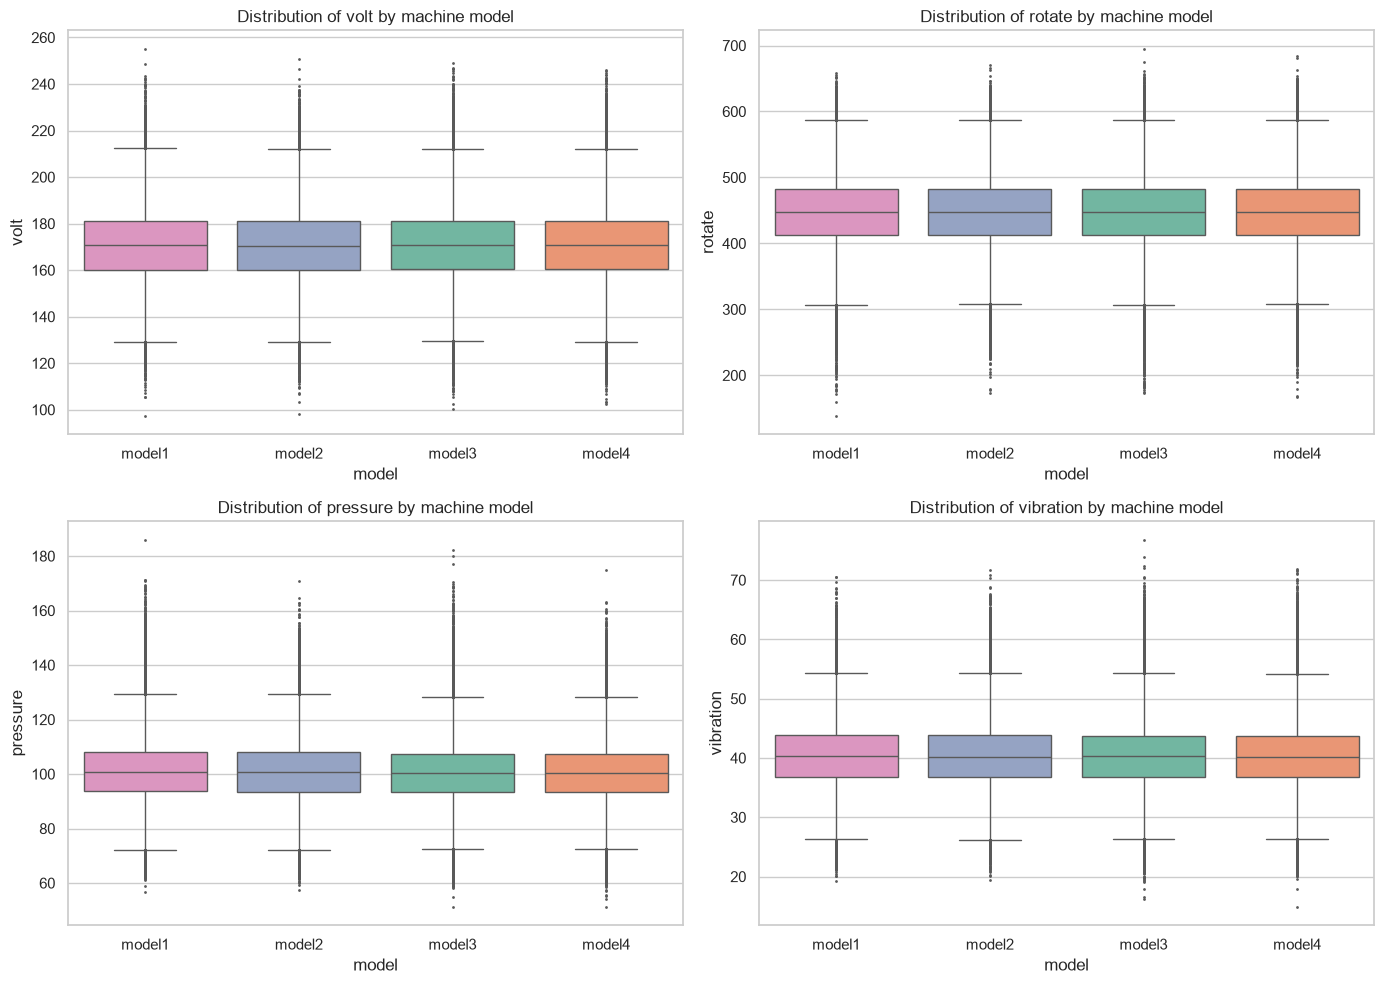

In [4]:
# Join telemetry with the static machine metadata
telemetry_merged = telemetry.merge(machines, on='machineID', how='left')

print('--- Distribution of machine models ---')
print(machines['model'].value_counts())

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
for i, sensor in enumerate(sensors):
    row, col = divmod(i, 2)
    sns.boxplot(
        data=telemetry_merged,
        x='model',
        y=sensor,
        order=sorted(machines['model'].unique()),
        ax=axes[row, col],
        palette='Set2',
        hue='model',
        legend=False,
        fliersize=1,
    )
    axes[row, col].set_title(f'Distribution of {sensor} by machine model')

plt.tight_layout()
plt.show()
del telemetry_merged

### Frequency of events by component

--- Error frequency by type ---


,frequency
errorID,
error1,1010
error2,988
error3,838
error4,727
error5,356


--- Maintenance records and failures by component ---


,maintenance_records,failures
comp,,
comp1,804,192
comp2,863,259
comp3,808,131
comp4,811,179


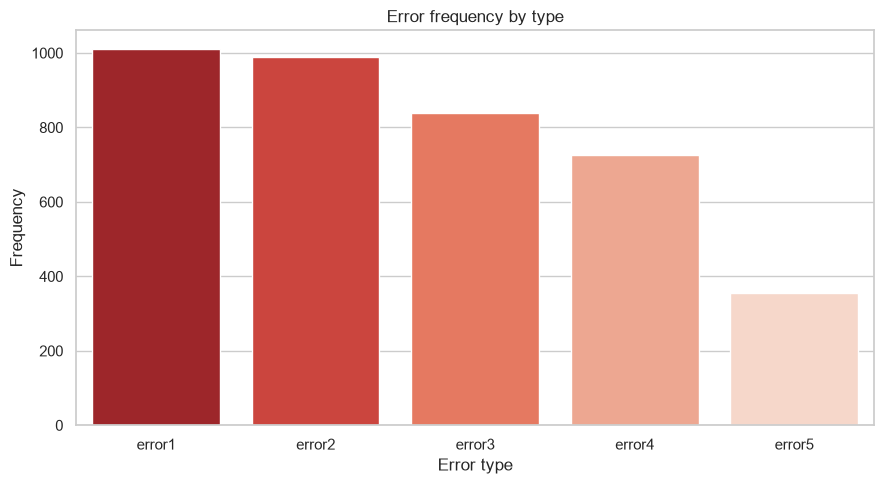

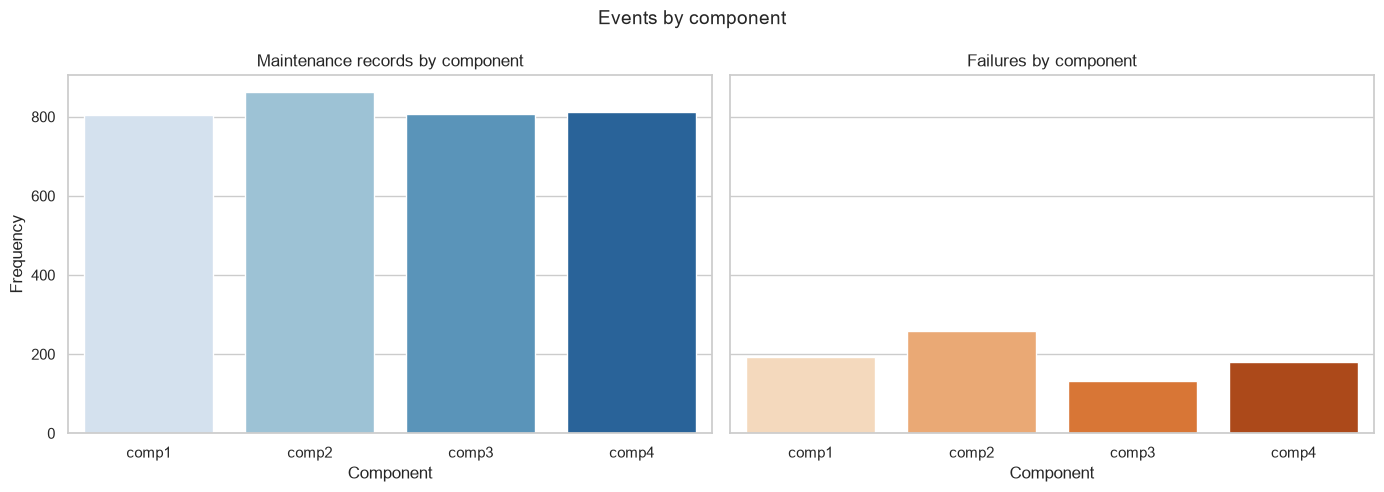

In [5]:
# Frequency of errors by type and of maintenance/failures by component
error_frequency = (
    errors.groupby('errorID')
    .size()
    .rename('frequency')
    .sort_values(ascending=False)
    .to_frame()
)

maintenance_frequency = maint.groupby('comp').size().rename('maintenance_records')
failure_frequency = failures.groupby('failure').size().rename('failures')
component_frequency = pd.concat(
    [maintenance_frequency, failure_frequency],
    axis=1,
).fillna(0).astype(int).sort_index()
component_frequency.index.name = 'comp'
print('--- Error frequency by type ---')
display(error_frequency)
print('--- Maintenance records and failures by component ---')
display(component_frequency)

# Errors by type
fig, ax = plt.subplots(figsize=(9, 5))
sns.barplot(
    data=error_frequency.reset_index(),
    x='errorID',
    y='frequency',
    hue='errorID',
    palette='Reds_r',
    legend=False,
    ax=ax,
)
ax.set_title('Error frequency by type')
ax.set_xlabel('Error type')
ax.set_ylabel('Frequency')
plt.tight_layout()
plt.show()

# Maintenance and failures by component
component_plot_data = component_frequency.reset_index().melt(
    id_vars='comp',
    var_name='event',
    value_name='frequency',
)
fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)
sns.barplot(
    data=component_plot_data[component_plot_data['event'] == 'maintenance_records'],
    x='comp',
    y='frequency',
    hue='comp',
    palette='Blues',
    legend=False,
    ax=axes[0],
)
sns.barplot(
    data=component_plot_data[component_plot_data['event'] == 'failures'],
    x='comp',
    y='frequency',
    hue='comp',
    palette='Oranges',
    legend=False,
    ax=axes[1],
)
axes[0].set_title('Maintenance records by component')
axes[1].set_title('Failures by component')
for ax in axes:
    ax.set_xlabel('Component')
    ax.set_ylabel('Frequency')

fig.suptitle('Events by component', fontsize=14)
plt.tight_layout()
plt.show()

### Failures over time, by machine model and by age

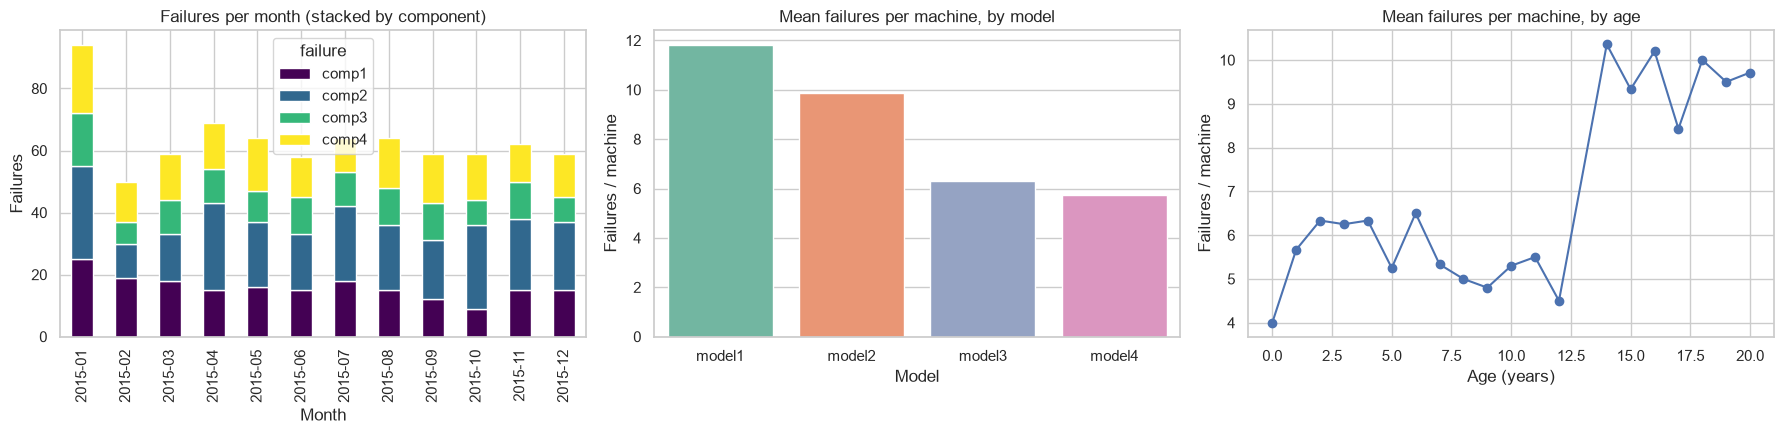

In [6]:
f = failures.merge(machines, on='machineID')
f['month'] = f['datetime'].dt.to_period('M').astype(str)
monthly = f.groupby(['month', 'failure']).size().unstack(fill_value=0)

failures_per_machine = machines.assign(
    n_failures=machines['machineID'].map(failures.groupby('machineID').size()).fillna(0)
)

fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
monthly.plot(kind='bar', stacked=True, ax=axes[0], colormap='viridis')
axes[0].set_title('Failures per month (stacked by component)')
axes[0].set_xlabel('Month'); axes[0].set_ylabel('Failures')

by_model = failures_per_machine.groupby('model')['n_failures'].mean()
sns.barplot(x=by_model.index, y=by_model.values, hue=by_model.index, palette='Set2', legend=False, ax=axes[1])
axes[1].set_title('Mean failures per machine, by model'); axes[1].set_xlabel('Model'); axes[1].set_ylabel('Failures / machine')

by_age = failures_per_machine.groupby('age')['n_failures'].mean()
axes[2].plot(by_age.index, by_age.values, marker='o')
axes[2].set_title('Mean failures per machine, by age'); axes[2].set_xlabel('Age (years)'); axes[2].set_ylabel('Failures / machine')
plt.tight_layout()
plt.show()

### Telemetry behaviour before a failure

The 72 hours before each failure (including the critical 48-hour window) are compared with healthy observations that have more than 72 hours to the next failure.

Pre-failure rows: 53,730 before de-duplication, 50,736 after (each row kept once).
--- Statistics: telemetry before a failure vs. healthy periods ---


volt                 rotate                 \
                           mean  median    std    mean  median    std   
state       period                                                      
healthy     healthy      170.59  170.50  15.33  447.68  448.49  51.83   
pre-failure 0-48 hours   175.86  175.22  17.88  418.41  420.81  64.17   
            48-72 hours  170.68  170.71  15.31  447.31  447.83  52.48   

                        pressure                vibration               
                            mean  median    std      mean median   std  
state       period                                                      
healthy     healthy       100.67  100.29  10.83     40.30  40.17  5.23  
pre-failure 0-48 hours    105.36  103.31  14.64     42.79  42.10  6.92  
            48-72 hours   100.80  100.55  10.93     40.26  40.21  5.28

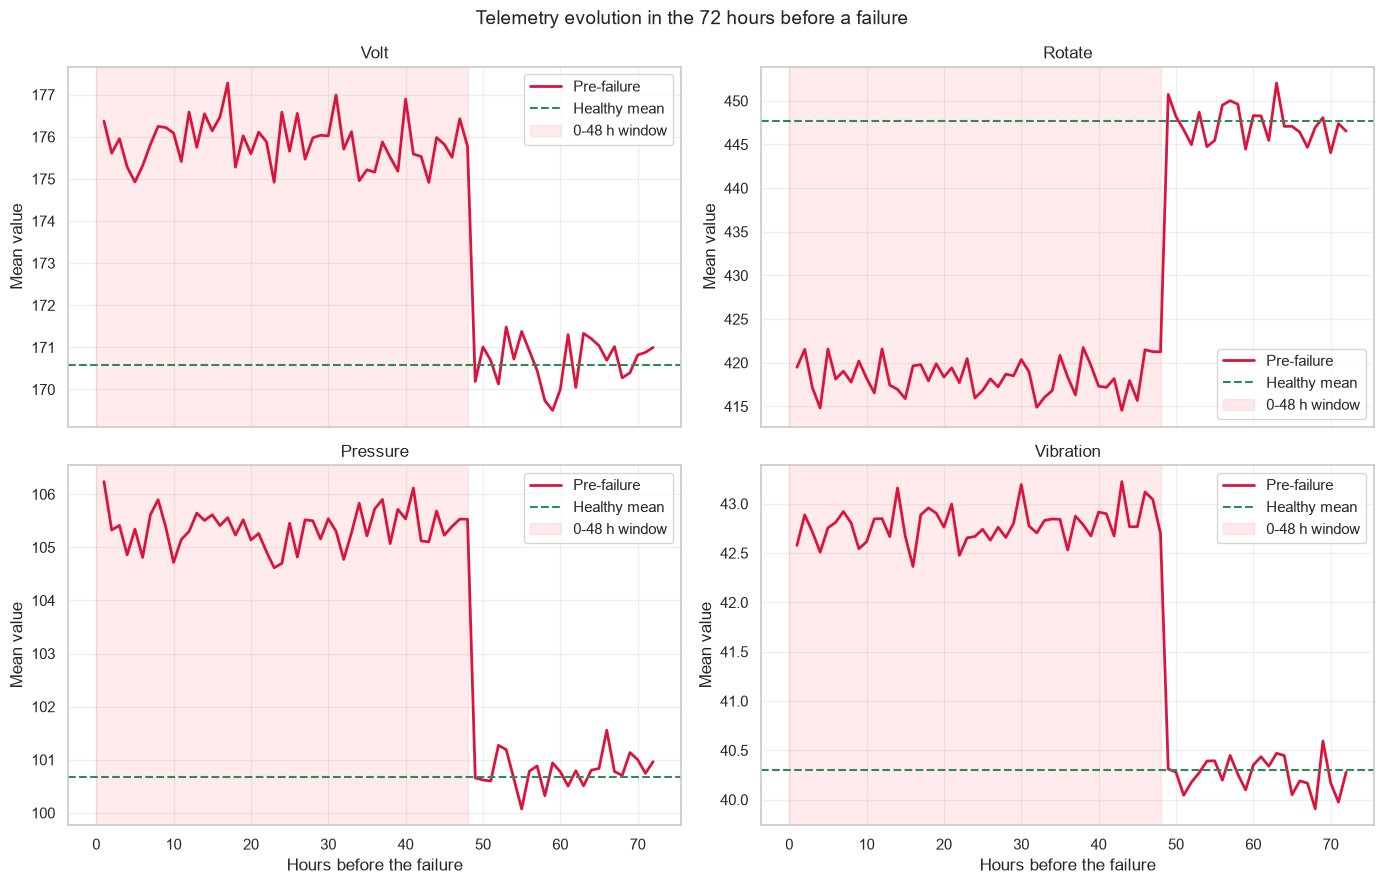

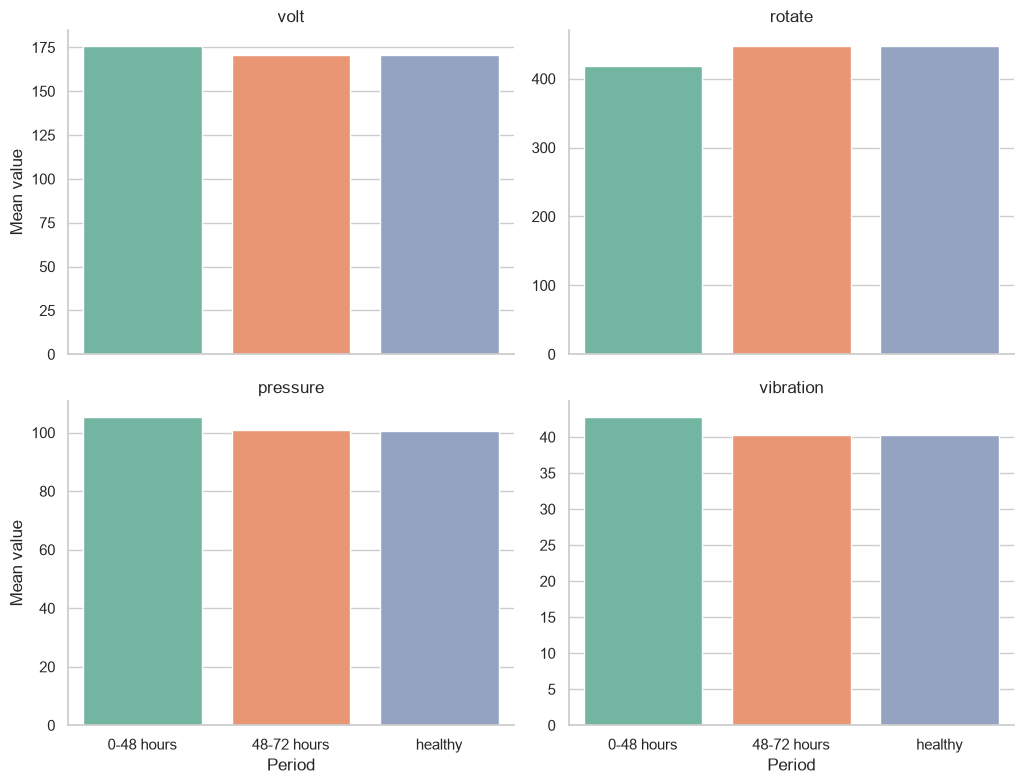

In [7]:
window_hours = 72

# One 72 h window per failure
tel_by_machine = {mid: g for mid, g in telemetry.groupby('machineID')}
failure_windows = []
for failure in failures.itertuples(index=False):
    g = tel_by_machine[failure.machineID]
    window = g[
        (g['datetime'] >= failure.datetime - pd.Timedelta(hours=window_hours))
        & (g['datetime'] < failure.datetime)
    ][['datetime', 'machineID'] + sensors].copy()
    window['hours_to_failure'] = (failure.datetime - window['datetime']).dt.total_seconds() / 3600
    window['component'] = failure.failure
    failure_windows.append(window)

pre_failure = pd.concat(failure_windows, ignore_index=True)
n_raw = len(pre_failure)
pre_failure = (
    pre_failure.sort_values(['hours_to_failure', 'component'])
    .drop_duplicates(['machineID', 'datetime'], keep='first')
    .reset_index(drop=True)
)
print(f'Pre-failure rows: {n_raw:,} before de-duplication, {len(pre_failure):,} after (each row kept once).')
pre_failure['state'] = 'pre-failure'
pre_failure['period'] = pd.cut(
    pre_failure['hours_to_failure'],
    bins=[0, 48, 72],
    labels=['0-48 hours', '48-72 hours'],
)

# Healthy = more than 72 h to the next failure (rows AT the failure hour are not healthy)
failure_events = failures[['machineID', 'datetime']].sort_values(['datetime', 'machineID'])
telemetry_sorted = telemetry.sort_values(['datetime', 'machineID']).copy()
healthy = pd.merge_asof(
    telemetry_sorted,
    failure_events.rename(columns={'datetime': 'next_failure'}),
    by='machineID',
    left_on='datetime',
    right_on='next_failure',
    direction='forward',
).copy()
healthy['hours_to_failure'] = (healthy['next_failure'] - healthy['datetime']).dt.total_seconds() / 3600
healthy = healthy[
    healthy['hours_to_failure'].isna() | (healthy['hours_to_failure'] > window_hours)
][['datetime', 'machineID'] + sensors].copy()
healthy['state'] = 'healthy'
healthy['period'] = 'healthy'

# Balance the healthy group so the comparison is not dominated by its size
healthy_sample = healthy.sample(n=min(len(healthy), len(pre_failure)), random_state=SEED).copy()
comparison = pd.concat(
    [pre_failure[['state', 'period'] + sensors], healthy_sample[['state', 'period'] + sensors]],
    ignore_index=True,
)

summary = comparison.groupby(['state', 'period'], observed=True)[sensors].agg(['mean', 'median', 'std']).round(2)
print('--- Statistics: telemetry before a failure vs. healthy periods ---')
display(summary)

# Evolution by hours remaining until the failure, with a healthy reference
failure_profile = pre_failure.groupby('hours_to_failure')[sensors].mean().sort_index(ascending=False)
healthy_baseline = healthy_sample[sensors].mean()

fig, axes = plt.subplots(2, 2, figsize=(14, 9), sharex=True)
for sensor, ax in zip(sensors, axes.flat):
    ax.plot(failure_profile.index, failure_profile[sensor], color='crimson', linewidth=2, label='Pre-failure')
    ax.axhline(healthy_baseline[sensor], color='seagreen', linestyle='--', label='Healthy mean')
    ax.axvspan(0, 48, color='red', alpha=0.08, label='0-48 h window')
    ax.set_title(sensor.capitalize())
    ax.set_ylabel('Mean value')
    ax.grid(True, alpha=0.3)
    ax.legend()

for ax in axes[1, :]:
    ax.set_xlabel('Hours before the failure')
    ax.invert_xaxis()
fig.suptitle('Telemetry evolution in the 72 hours before a failure', fontsize=14)
plt.tight_layout()
plt.show()

# Direct comparison of the 0-48 h and 48-72 h windows against the healthy period
period_summary = comparison.groupby('period', observed=True)[sensors].mean().reset_index()
period_plot = period_summary.melt(id_vars='period', var_name='sensor', value_name='mean_value')
g = sns.catplot(
    data=period_plot,
    x='period',
    y='mean_value',
    col='sensor',
    kind='bar',
    col_wrap=2,
    height=4,
    aspect=1.3,
    sharey=False,
    palette='Set2',
    hue='period',
    legend=False,
)
g.set_axis_labels('Period', 'Mean value')
g.set_titles('{col_name}')
plt.tight_layout()
plt.show()

### Errors and per-component sensor deviation before a failure

--- Errors per 100 machine-hours ---


,error1,error2,error3,error4,error5
bucket,,,,,
healthy,0.10,0.08,0.07,0.07,0.03
48-72h,0.09,0.10,0.08,0.06,0.02
24-48h,0.11,0.06,0.10,0.05,0.02
0-24h,1.14,1.58,1.58,0.86,1.04


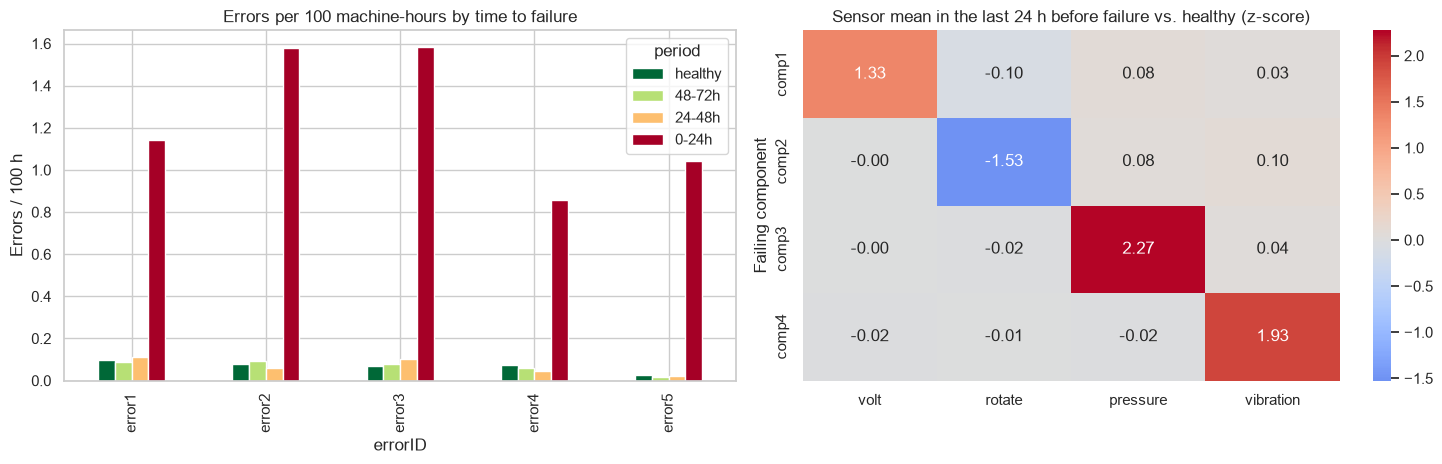

In [8]:
err_hourly = errors.groupby(['machineID', 'datetime', 'errorID']).size().unstack(fill_value=0)
err_hourly = err_hourly.reindex(columns=ERROR_TYPES, fill_value=0).reset_index()

pf = pre_failure[['machineID', 'datetime', 'hours_to_failure', 'component'] + sensors].merge(
    err_hourly, on=['machineID', 'datetime'], how='left')
pf['bucket'] = pd.cut(pf['hours_to_failure'], bins=[0, 24, 48, 72],
                      labels=['0-24h', '24-48h', '48-72h']).astype(object)
hs = healthy_sample[['machineID', 'datetime'] + sensors].merge(err_hourly, on=['machineID', 'datetime'], how='left')
hs['bucket'] = 'healthy'
rate_data = pd.concat([pf, hs], ignore_index=True)
rate_data[ERROR_TYPES] = rate_data[ERROR_TYPES].fillna(0)

BUCKET_ORDER = ['healthy', '48-72h', '24-48h', '0-24h']
err_rate = (rate_data.groupby('bucket')[ERROR_TYPES].mean() * 100).loc[BUCKET_ORDER]
print('--- Errors per 100 machine-hours ---')
display(err_rate.round(2))

z = (pf[pf['hours_to_failure'] <= 24].groupby('component')[sensors].mean() - hs[sensors].mean()) / hs[sensors].std()

fig, axes = plt.subplots(1, 2, figsize=(15, 4.8))
err_rate.T.plot(kind='bar', ax=axes[0], colormap='RdYlGn_r')
axes[0].set_title('Errors per 100 machine-hours by time to failure')
axes[0].set_xlabel('errorID'); axes[0].set_ylabel('Errors / 100 h'); axes[0].legend(title='period')
sns.heatmap(z, annot=True, fmt='.2f', cmap='coolwarm', center=0, ax=axes[1])
axes[1].set_title('Sensor mean in the last 24 h before failure vs. healthy (z-score)')
axes[1].set_xlabel(''); axes[1].set_ylabel('Failing component')
plt.tight_layout()
plt.show()
del pf, hs, rate_data, healthy, telemetry_sorted

## 1.2 Relationship between maintenance records and failures

Every analysis below relates the two files by `machineID` and component.

**Important detail:** the replacement caused by a failure is logged with the **same timestamp** as the failure. So "the last maintenance before a failure" must use records *strictly before* the failure; otherwise the failure's own replacement record is matched and every failure looks as if it had been maintained "0 days ago".

--- Failures with their previous replacement ---


,failure_datetime,machineID,component,maintenance_datetime,days_since_maintenance,maintenance_before_failure
0,2015-01-02 03:00:00,16,comp1,2014-11-13 06:00:00,49.875,True
1,2015-01-02 03:00:00,16,comp3,2014-10-29 06:00:00,64.875,True
2,2015-01-02 03:00:00,17,comp4,2015-01-01 06:00:00,0.875,True
3,2015-01-02 03:00:00,22,comp1,2014-12-28 06:00:00,4.875,True
4,2015-01-02 03:00:00,35,comp1,2014-12-13 06:00:00,19.875,True


--- Failures by days since the previous replacement of the same component ---


maintenance_age,0-15 days,16-30 days,31-60 days,61-90 days,More than 90 days,total_failures,with_previous_replacement
component,,,,,,,
comp1,6,2,85,35,64,192,192
comp2,0,76,83,41,59,259,259
comp3,1,1,55,28,46,131,131
comp4,1,0,66,41,71,179,179


--- Replacements followed by a failure of the same component within 90 days ---


,maintenance_records,followed_by_failure_90_days,percent_followed_by_failure
component,,,
comp1,804,188,23.38
comp2,863,317,36.73
comp3,808,115,14.23
comp4,811,161,19.85


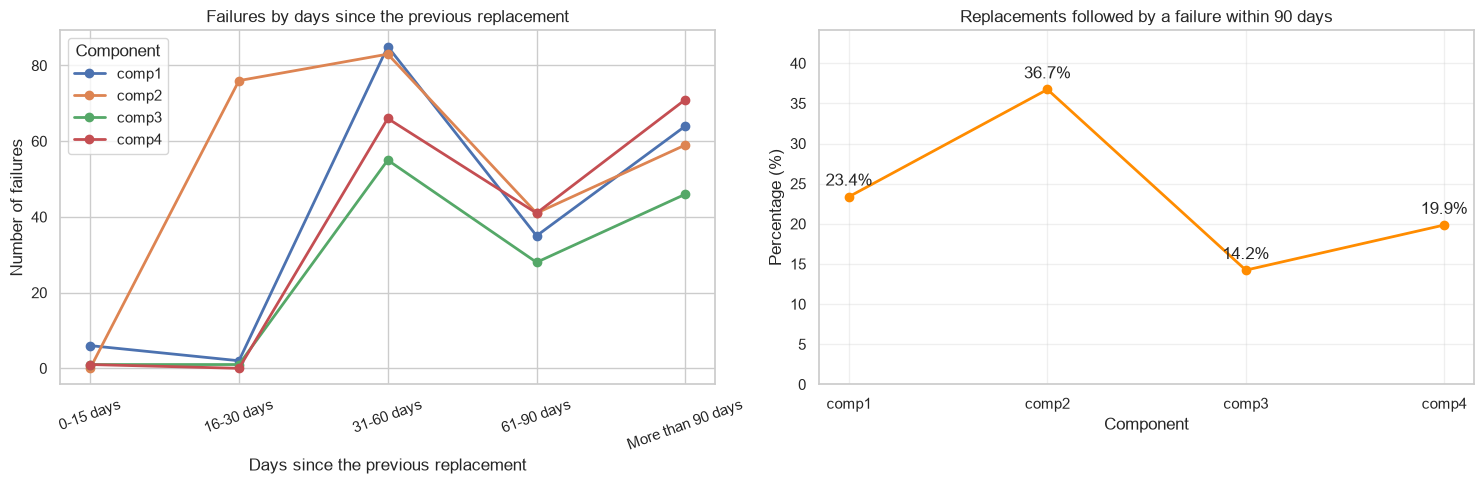

In [9]:
maintenance_events = maint.rename(columns={'comp': 'component'})[['datetime', 'machineID', 'component']].sort_values(
    ['datetime', 'machineID', 'component']
).copy()
failure_events_comp = failures.rename(columns={'failure': 'component'})[['datetime', 'machineID', 'component']].sort_values(
    ['datetime', 'machineID', 'component']
).copy()

# Last replacement of the same machine and component STRICTLY BEFORE each failure
failure_maintenance = pd.merge_asof(
    failure_events_comp,
    maintenance_events.rename(columns={'datetime': 'maintenance_datetime'}),
    by=['machineID', 'component'],
    left_on='datetime',
    right_on='maintenance_datetime',
    direction='backward',
    allow_exact_matches=False,
).rename(columns={'datetime': 'failure_datetime'})
failure_maintenance['days_since_maintenance'] = (
    failure_maintenance['failure_datetime'] - failure_maintenance['maintenance_datetime']
).dt.total_seconds() / (24 * 3600)
failure_maintenance['maintenance_before_failure'] = failure_maintenance['maintenance_datetime'].notna()
print('--- Failures with their previous replacement ---')
display(failure_maintenance.head())

# Summary by component and time since the previous replacement
time_windows = [0, 15, 30, 60, 90, np.inf]
time_labels = ['0-15 days', '16-30 days', '31-60 days', '61-90 days', 'More than 90 days']
failure_maintenance['maintenance_age'] = pd.cut(
    failure_maintenance['days_since_maintenance'], bins=time_windows, labels=time_labels, include_lowest=True,
)
relationship_summary = failure_maintenance.groupby(
    ['component', 'maintenance_age'], observed=False,
).size().unstack(fill_value=0)
relationship_summary['total_failures'] = failure_maintenance.groupby('component').size()
relationship_summary['with_previous_replacement'] = failure_maintenance.groupby('component')['maintenance_before_failure'].sum()
print('--- Failures by days since the previous replacement of the same component ---')
display(relationship_summary)

# Replacements followed by a failure of the same component within 90 days (strictly after the replacement)
maintenance_failure = pd.merge_asof(
    maintenance_events,
    failure_events_comp.rename(columns={'datetime': 'next_failure_datetime'}),
    by=['machineID', 'component'],
    left_on='datetime',
    right_on='next_failure_datetime',
    direction='forward',
    allow_exact_matches=False,
).rename(columns={'datetime': 'maintenance_datetime'})
maintenance_failure['days_to_failure'] = (
    maintenance_failure['next_failure_datetime'] - maintenance_failure['maintenance_datetime']
).dt.total_seconds() / (24 * 3600)
maintenance_failure['failure_within_90_days'] = maintenance_failure['days_to_failure'].between(0, 90, inclusive='both')
maintenance_summary = maintenance_failure.groupby('component').agg(
    maintenance_records=('maintenance_datetime', 'size'),
    followed_by_failure_90_days=('failure_within_90_days', 'sum'),
)
maintenance_summary['percent_followed_by_failure'] = (
    maintenance_summary['followed_by_failure_90_days'] / maintenance_summary['maintenance_records'] * 100
).round(2)
print('--- Replacements followed by a failure of the same component within 90 days ---')
display(maintenance_summary)

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
for component, values in relationship_summary[time_labels].iterrows():
    axes[0].plot(time_labels, values, marker='o', linewidth=2, label=component)
axes[0].set_title('Failures by days since the previous replacement')
axes[0].set_xlabel('Days since the previous replacement')
axes[0].set_ylabel('Number of failures')
axes[0].tick_params(axis='x', rotation=20)
axes[0].legend(title='Component')

percentage_data = maintenance_summary.reset_index()
axes[1].plot(percentage_data['component'], percentage_data['percent_followed_by_failure'],
             marker='o', color='darkorange', linewidth=2)
for _, row in percentage_data.iterrows():
    axes[1].annotate(f"{row['percent_followed_by_failure']:.1f}%",
                     (row['component'], row['percent_followed_by_failure']),
                     textcoords='offset points', xytext=(0, 8), ha='center')
axes[1].set_title('Replacements followed by a failure within 90 days')
axes[1].set_xlabel('Component')
axes[1].set_ylabel('Percentage (%)')
axes[1].set_ylim(0, max(percentage_data['percent_followed_by_failure']) * 1.2)
axes[1].grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

### Which maintenance records are a consequence of a failure?

The reliable criterion is an **exact match** on `(machineID, comp, datetime)` with a row of `PdM_failures`. The heuristic "any maintenance within 90 days after a failure" over-counts, because it also captures scheduled replacements that just happen to follow a failure.

In [10]:
fail_keys = (failures.rename(columns={'failure': 'comp'})[['datetime', 'machineID', 'comp']]
             .drop_duplicates().assign(failure_driven=True))
maint_flag = maint.merge(fail_keys, on=['datetime', 'machineID', 'comp'], how='left')
maint_flag['failure_driven'] = maint_flag['failure_driven'].fillna(False).astype(bool)

# Lag between each failure and the first replacement record of the same machine/component at or after it
lag = pd.merge_asof(
    failures.rename(columns={'failure': 'comp'}).sort_values('datetime'),
    maint[['datetime', 'machineID', 'comp']].rename(columns={'datetime': 'replacement_time'}).sort_values('replacement_time'),
    by=['machineID', 'comp'], left_on='datetime', right_on='replacement_time',
    direction='forward', allow_exact_matches=True,
)
lag['lag_hours'] = (lag['replacement_time'] - lag['datetime']).dt.total_seconds() / 3600

summary_maint = pd.DataFrame({
    'maintenance_records': maint_flag.groupby('comp').size(),
    'failure_driven (exact match)': maint_flag.groupby('comp')['failure_driven'].sum(),
    'scheduled': maint_flag.groupby('comp')['failure_driven'].apply(lambda s: (~s).sum()),
    'failures': failures.groupby('failure').size(),
})
summary_maint.loc['total'] = summary_maint.sum()
summary_maint['% failure_driven'] = (
    100 * summary_maint['failure_driven (exact match)'] / summary_maint['maintenance_records']
).round(1)
print('--- Maintenance records: failure-driven vs. scheduled ---')
display(summary_maint)

print('--- Lag (hours) between each failure and the first replacement record of the same component ---')
display(lag['lag_hours'].value_counts(dropna=False).rename('failures').to_frame())
print('Hour of day of failures:', failures['datetime'].dt.hour.value_counts().to_dict())
print('Hour of day of maintenance records:', maint['datetime'].dt.hour.value_counts().to_dict())

sched = maint_flag[~maint_flag['failure_driven']].sort_values(['machineID', 'comp', 'datetime']).copy()
sched['days_since_prev_scheduled'] = sched.groupby(['machineID', 'comp'])['datetime'].diff().dt.total_seconds() / 86400
print('--- Days between consecutive scheduled replacements (same machine and component) ---')
display(sched.groupby('comp')['days_since_prev_scheduled'].describe().round(1))

# Why the exact timestamp matters: "hours since last replacement" evaluated at t = failure time
fe = failures.rename(columns={'failure': 'comp'}).sort_values('datetime')
rm = maint[['datetime', 'machineID', 'comp']].rename(columns={'datetime': 'last_replacement'}).sort_values('last_replacement')
rows = []
for allow_exact, rule in [(True, 'records with time <= t (inclusive)'), (False, 'records with time < t (strict)')]:
    m = pd.merge_asof(fe, rm, by=['machineID', 'comp'], left_on='datetime', right_on='last_replacement',
                      direction='backward', allow_exact_matches=allow_exact)
    h = (m['datetime'] - m['last_replacement']).dt.total_seconds() / 3600
    rows.append({'rule used to compute the feature': rule,
                 '% of failures where feature = 0 h at t = failure time': round(100 * (h == 0).mean(), 1),
                 'median hours since replacement': round(h.median(), 1)})
print('--- Leakage demo: feature value at t = failure time ---')
display(pd.DataFrame(rows).set_index('rule used to compute the feature'))

--- Maintenance records: failure-driven vs. scheduled ---


,maintenance_records,failure_driven (exact match),scheduled,failures,% failure_driven
comp1,804,183,621,192,22.8
comp2,863,256,607,259,29.7
comp3,808,128,680,131,15.8
comp4,811,176,635,179,21.7
total,3286,743,2543,761,22.6


--- Lag (hours) between each failure and the first replacement record of the same component ---


,failures
lag_hours,
0.0,743
339.0,2
699.0,2
291.0,1
1467.0,1
435.0,1
363.0,1
1443.0,1
2427.0,1


Hour of day of failures: {6: 743, 3: 18}
Hour of day of maintenance records: {6: 3286}
--- Days between consecutive scheduled replacements (same machine and component) ---


,count,mean,std,min,25%,50%,75%,max
comp,,,,,,,,
comp1,521.0,77.7,79.6,11.0,15.0,45.0,120.0,492.0
comp2,507.0,78.4,82.0,5.0,15.0,45.0,105.0,500.0
comp3,580.0,70.6,79.0,15.0,15.0,45.0,90.0,535.0
comp4,535.0,71.5,81.1,15.0,15.0,30.0,90.0,470.0


--- Leakage demo: feature value at t = failure time ---


,% of failures where feature = 0 h at t = failure time,median hours since replacement
rule used to compute the feature,,
records with time <= t (inclusive),97.6,0.0
records with time < t (strict),0.0,1608.0


### Questions and answers

**Which maintenance records are a consequence of a failure?**

Those whose `(machineID, comp, datetime)` coincides with a row of `PdM_failures` (see the table above). Practically every failure has its own replacement logged at the same timestamp; the few exceptions are failures logged at 03:00 whose replacement appears in the 06:00 batch (see the lag table). These corrective records are roughly a quarter of all maintenance records, and the rest are scheduled replacements, always logged at 06:00. The looser rule "maintenance within 90 days after a failure" over-counts, since it also captures scheduled replacements that merely follow a failure.

**What is the risk of using them as an input variable?**

The corrective record carries the **same timestamp as the failure**, so it contains the answer. If a feature such as *hours since last replacement* is computed with records at `time <= t`, then at `t = failure time` it is exactly 0 for the failing component (table above). More generally:

1. A record dated at or after `t` is future information and must never reach the model.
2. A flag such as "this replacement was corrective" is a failure indicator in disguise and cannot be used.
3. The *time since the last replacement* of **past** records is legitimate (it is known at `t`), but only if computed with records strictly before `t`. That is the rule used in section 1.4.

## 1.3 Label construction

For each machine `m` and hour `t`, with `H = 24`:

* `y_comp_k = 1` if component `k` fails in the interval **(t, t + H]** (the interval excludes `t`, so the failure hour is not a positive row of its own failure).
* `y_binary = 1` if any component fails in `(t, t + H]`.
* `y_multiclass` is 0 (`none`) or the component of the **nearest** failure in the window (1 to 4 for `comp1` to `comp4`).

Two components can fail in the same hour, and a second failure can fall inside the same window. For the multiclass label the nearest failure wins and ties go to the lowest component number; the per-component columns `y_comp1` to `y_comp4` keep the full multi-label information, and the number of affected rows is reported below. Rows are **not** filtered based on future events.

In [11]:
def build_labels(keys, failures_df, horizon=H):
    """Labels for hour t from failures in (t, t + horizon]. `keys`: machineID, datetime, RangeIndex."""
    htf = hours_to_next_event(keys, failures_df, 'failure', COMPS)
    in_window = htf <= horizon  # NaN compares as False; hours are strictly > 0 by construction
    labels = pd.DataFrame(in_window.astype('int8'), columns=[f'y_{c}' for c in COMPS], index=keys.index)
    labels['y_binary'] = in_window.any(axis=1).astype('int8')
    nearest = np.nan_to_num(htf, nan=np.inf).argmin(axis=1) + 1
    labels['y_multiclass'] = np.where(labels['y_binary'] == 1, nearest, 0).astype('int8')
    labels['n_components_in_window'] = in_window.sum(axis=1).astype('int8')
    return labels


# Global label analysis before splitting
telemetry_labeled = pd.concat(
    [telemetry[['machineID', 'datetime']], build_labels(telemetry[['machineID', 'datetime']], failures, H)], axis=1)

print('--- Binary positive rate over the whole of 2015 ---')
binary_global = pd.DataFrame({
    'rows': [len(telemetry_labeled)],
    'positives': [telemetry_labeled['y_binary'].sum()],
})
binary_global['positive_rate'] = (binary_global['positives'] / binary_global['rows']).round(4)
display(binary_global)

print('--- Multiclass label distribution ---')
multiclass_global = telemetry_labeled['y_multiclass'].map(dict(enumerate(CLASS_NAMES))).value_counts(normalize=True).rename('proportion').to_frame()
multiclass_global['rows'] = telemetry_labeled['y_multiclass'].map(dict(enumerate(CLASS_NAMES))).value_counts()
display(multiclass_global.reindex(CLASS_NAMES))

print('--- Positive rate per component (over all rows) ---')
component_positive_global = pd.DataFrame({
    'positives': [telemetry_labeled[f'y_{c}'].sum() for c in COMPS],
    'total_rows': len(telemetry_labeled),
}, index=COMPS)
component_positive_global['positive_rate'] = (component_positive_global['positives'] / component_positive_global['total_rows']).round(4)
display(component_positive_global)
print('Rows with more than one failing component in the window:', int((telemetry_labeled['n_components_in_window'] > 1).sum()))
del telemetry_labeled

--- Binary positive rate over the whole of 2015 ---


,rows,positives,positive_rate
0,876100,17184,0.0196


--- Multiclass label distribution ---


,proportion,rows
y_multiclass,,
none,0.980386,858916
comp1,0.005229,4581
comp2,0.006838,5991
comp3,0.003311,2901
comp4,0.004236,3711


--- Positive rate per component (over all rows) ---


,positives,total_rows,positive_rate
comp1,4581,876100,0.0052
comp2,6207,876100,0.0071
comp3,3135,876100,0.0036
comp4,4287,876100,0.0049


Rows with more than one failing component in the window: 1026


## 1.4 Feature engineering for the baseline

All features are causal (only information up to `t`):

| Group | Features |
|---|---|
| Raw sensors | `volt, rotate, pressure, vibration` at `t` |
| Rolling statistics | mean and standard deviation of each sensor over the last **3 h** and **24 h** (window `(t-w, t]`) |
| Errors | count of each `errorID` and total count in `(t-24h, t]` |
| Replacements | hours since the last replacement of each component, using records strictly before `t` (records from 2014 included) |
| Static | machine `model` (categorical) and `age` |

Rolling windows and the replacement history may use data before the start of each split, which the rules allow.

In [12]:
def build_features(telemetry_df, errors_df, maint_df, machines_df):
    """Causal features for every row of `telemetry_df` (sorted by machineID, datetime; RangeIndex)."""
    keys_ = telemetry_df[['machineID', 'datetime']]
    feats = telemetry_df[['machineID', 'datetime'] + sensors].copy()

    # Rolling mean/std over (t-w, t]
    grouped = telemetry_df.set_index('datetime').groupby('machineID')[sensors]
    for w in (3, 24):
        roll = grouped.rolling(f'{w}h', min_periods=1)
        mean, std = roll.mean(), roll.std()
        assert (mean.index.get_level_values('datetime').values == telemetry_df['datetime'].values).all()
        for s in sensors:
            feats[f'{s}_mean_{w}h'] = mean[s].values
            feats[f'{s}_std_{w}h'] = std[s].fillna(0).values

    # Error counts in the last 24 h
    err_counts = count_events_in_window(keys_, errors_df, 'errorID', ERROR_TYPES, 24)
    for j, e in enumerate(ERROR_TYPES):
        feats[f'{e}_count_24h'] = err_counts[:, j]
    feats['errors_total_24h'] = err_counts.sum(axis=1)

    # Hours since the last replacement of each component (strictly before t)
    since = hours_since_last_event(keys_, maint_df, 'comp', COMPS, strict=True)
    for j, c in enumerate(COMPS):
        feats[f'hours_since_replacement_{c}'] = since[:, j]

    # Static
    static = machines_df.set_index('machineID')
    feats['model'] = keys_['machineID'].map(static['model']).values
    feats['age'] = keys_['machineID'].map(static['age']).values

    num_cols = [c for c in feats.columns if c not in ('machineID', 'datetime', 'model')]
    feats[num_cols] = feats[num_cols].astype('float32')
    return feats


# Feature engineering over the whole history (causal; no statistics are fitted here)
analysis_base = build_features(telemetry, errors, maint, machines)
analysis_variables = [c for c in analysis_base.columns if c not in telemetry.columns]
print(f'{len(analysis_variables)} generated variables:', analysis_variables)
display(analysis_base[analysis_variables].describe(include='all').T)
print('This cell uses the whole history but only looks backwards; the split happens in the next section.')

28 generated variables: ['volt_mean_3h', 'volt_std_3h', 'rotate_mean_3h', 'rotate_std_3h', 'pressure_mean_3h', 'pressure_std_3h', 'vibration_mean_3h', 'vibration_std_3h', 'volt_mean_24h', 'volt_std_24h', 'rotate_mean_24h', 'rotate_std_24h', 'pressure_mean_24h', 'pressure_std_24h', 'vibration_mean_24h', 'vibration_std_24h', 'error1_count_24h', 'error2_count_24h', 'error3_count_24h', 'error4_count_24h', 'error5_count_24h', 'errors_total_24h', 'hours_since_replacement_comp1', 'hours_since_replacement_comp2', 'hours_since_replacement_comp3', 'hours_since_replacement_comp4', 'model', 'age']


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
volt_mean_3h,876100.0,NaN,NaN,NaN,170.777542,9.500616,125.532509,164.439522,170.430733,176.618286,241.420715
volt_std_3h,876100.0,NaN,NaN,NaN,13.301185,6.963166,0.0,8.038538,12.502377,17.677474,59.439209
rotate_mean_3h,876100.0,NaN,NaN,NaN,446.605469,33.120853,194.464554,427.501648,448.364349,468.433662,590.642944
rotate_std_3h,876100.0,NaN,NaN,NaN,44.464149,23.221848,0.0,26.931918,41.801102,59.077621,194.598434
pressure_mean_3h,876100.0,NaN,NaN,NaN,100.858734,7.415163,72.118637,96.231201,100.237282,104.407097,166.190048
pressure_std_3h,876100.0,NaN,NaN,NaN,8.885518,4.657044,0.0,5.371941,8.341761,11.797358,38.249786
vibration_mean_3h,876100.0,NaN,NaN,NaN,40.384914,3.477885,22.973289,38.148155,40.150339,42.229484,69.311325
vibration_std_3h,876100.0,NaN,NaN,NaN,4.440752,2.323538,0.0,2.686098,4.168951,5.899563,19.166876
volt_mean_24h,876100.0,NaN,NaN,NaN,170.777786,4.733903,136.878586,168.071651,170.210892,172.462967,223.853302
volt_std_24h,876100.0,NaN,NaN,NaN,14.914907,2.272971,0.0,13.354514,14.852775,16.394493,50.02581


This cell uses the whole history but only looks backwards; the split happens in the next section.


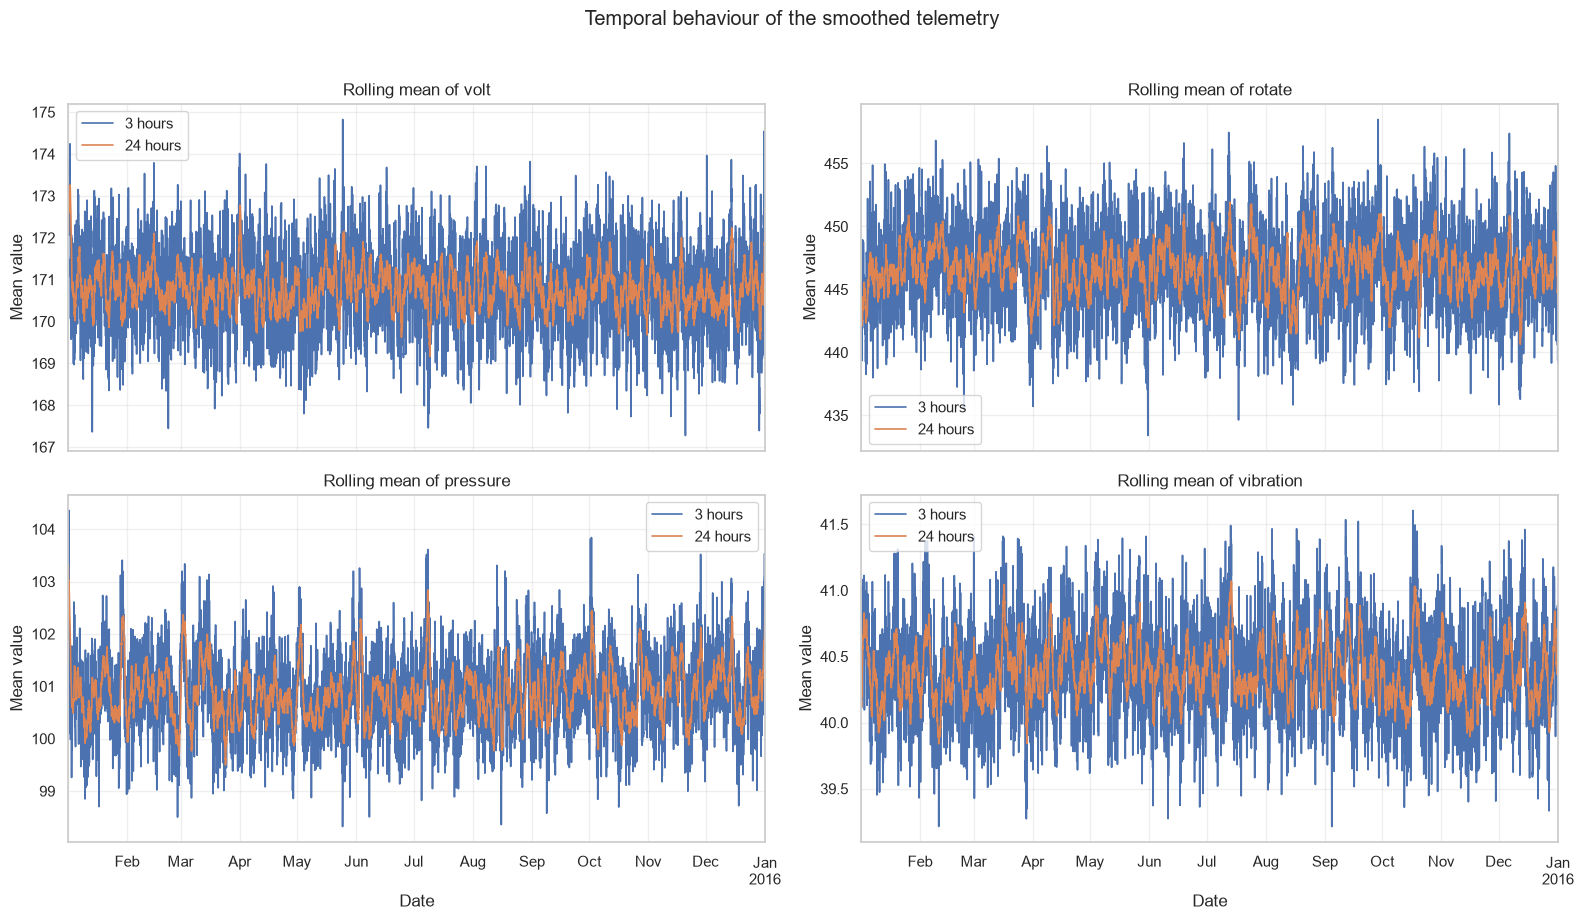

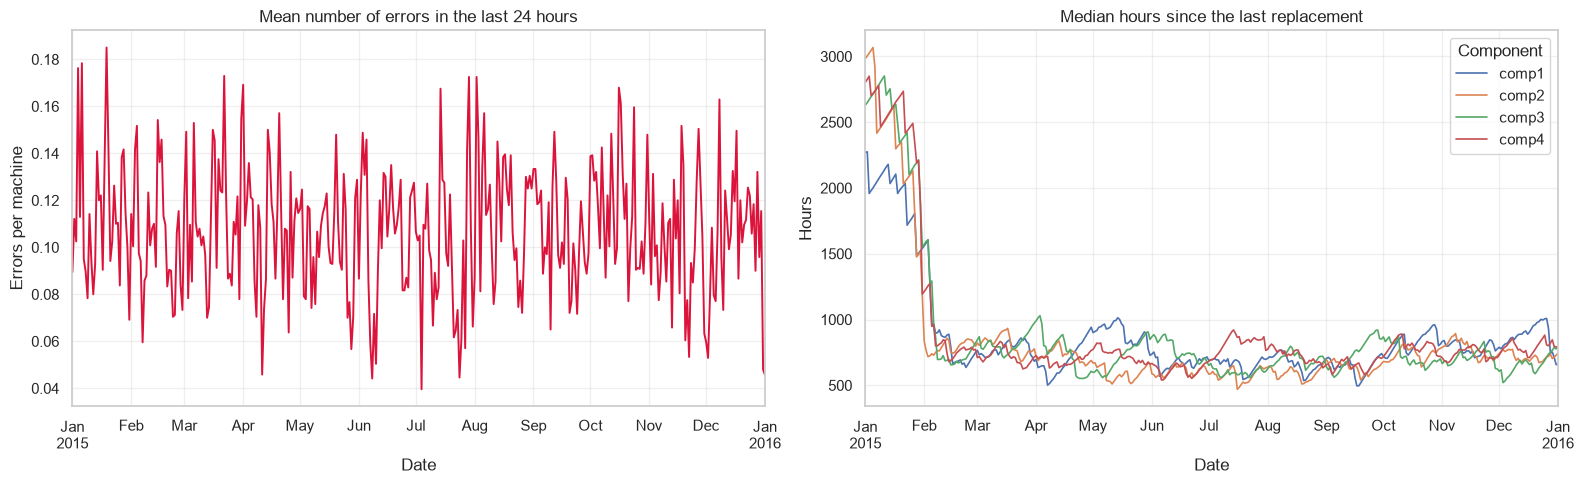

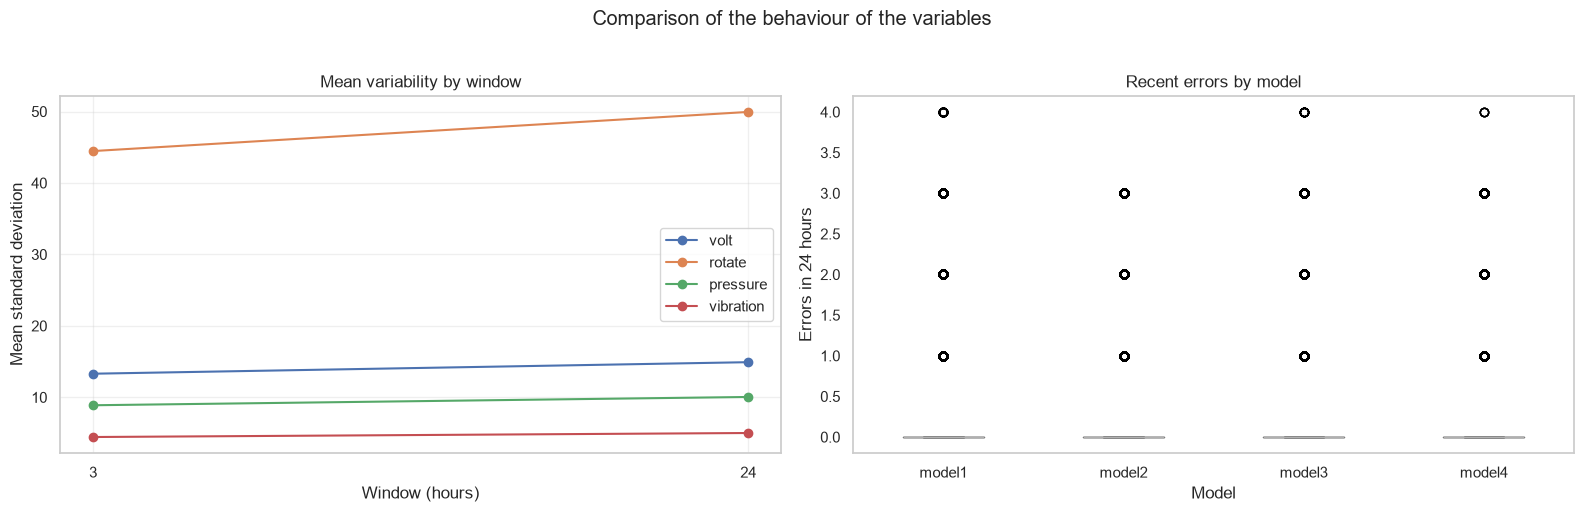

In [13]:
# Figures to observe the behaviour of the engineered variables
fig, axes = plt.subplots(2, 2, figsize=(16, 9), sharex=True)
for ax, sensor in zip(axes.ravel(), sensors):
    series = analysis_base.groupby('datetime')[[f'{sensor}_mean_3h', f'{sensor}_mean_24h']].mean()
    series.plot(ax=ax, linewidth=1.2)
    ax.set_title(f'Rolling mean of {sensor}')
    ax.set_xlabel('Date')
    ax.set_ylabel('Mean value')
    ax.legend(['3 hours', '24 hours'])
    ax.grid(True, alpha=0.3)
plt.suptitle('Temporal behaviour of the smoothed telemetry', y=1.02)
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(16, 5))
daily_errors = analysis_base.set_index('datetime')['errors_total_24h'].resample('D').mean()
daily_errors.plot(ax=axes[0], color='crimson', linewidth=1.4)
axes[0].set_title('Mean number of errors in the last 24 hours')
axes[0].set_xlabel('Date')
axes[0].set_ylabel('Errors per machine')
axes[0].grid(True, alpha=0.3)

replacement_cols = [f'hours_since_replacement_{c}' for c in COMPS]
analysis_base.set_index('datetime')[replacement_cols].rename(
    columns=lambda c: c.replace('hours_since_replacement_', '')
).groupby(pd.Grouper(freq='D')).median().plot(ax=axes[1], linewidth=1.2)
axes[1].set_title('Median hours since the last replacement')
axes[1].set_xlabel('Date')
axes[1].set_ylabel('Hours')
axes[1].legend(title='Component')
axes[1].grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(16, 5))
for sensor in sensors:
    axes[0].plot([3, 24], [analysis_base[f'{sensor}_std_3h'].mean(), analysis_base[f'{sensor}_std_24h'].mean()],
                 marker='o', label=sensor)
axes[0].set_title('Mean variability by window')
axes[0].set_xlabel('Window (hours)')
axes[0].set_ylabel('Mean standard deviation')
axes[0].set_xticks([3, 24])
axes[0].legend()
axes[0].grid(True, alpha=0.3)

analysis_base.boxplot(column='errors_total_24h', by='model', ax=axes[1], grid=False)
axes[1].set_title('Recent errors by model')
axes[1].set_xlabel('Model')
axes[1].set_ylabel('Errors in 24 hours')
fig.suptitle('Comparison of the behaviour of the variables', y=1.02)
plt.tight_layout()
plt.show()

## Temporal split pipeline

The pipeline builds the labels, assigns every row to a split **only by its timestamp `t`**, and returns the datasets. Rows inside the `H`-hour margin before each boundary are labeled `gap` and discarded (`gap` also holds the 7 telemetry rows per machine dated 1 Jan 2016, which fall outside every period). No row is dropped because of what happens after it.

In [14]:
def build_temporal_pipeline(telemetry, failures, features=None, horizon_hours=24):
    """Uses causal features, builds the H-hour labels and splits temporally by timestamp."""
    telemetry_base = (features.copy() if features is not None else telemetry.copy()).reset_index(drop=True)
    labels = build_labels(telemetry_base[['machineID', 'datetime']], failures, horizon_hours)
    labeled = pd.concat([telemetry_base, labels], axis=1)

    margin = pd.Timedelta(hours=horizon_hours)
    bounds = {
        'train': (T0, T_VAL - margin),
        'validation': (T_VAL, T_TEST - margin),
        'test': (T_TEST, T_END),
    }
    conditions = [labeled['datetime'].ge(a) & labeled['datetime'].lt(b) for a, b in bounds.values()]
    labeled['split'] = np.select(conditions, list(bounds), default='gap')
    labeled = labeled[labeled['split'] != 'gap'].copy()

    label_columns = list(labels.columns) + ['split']
    feature_columns = [c for c in labeled.columns if c not in label_columns]
    datasets = {}
    for split in ['train', 'validation', 'test']:
        split_data = labeled[labeled['split'].eq(split)]
        datasets[split] = {
            'X': split_data[feature_columns].copy(),
            'y_binary': split_data['y_binary'].copy(),
            'y_multiclass': split_data['y_multiclass'].copy(),
        }
    return labeled, datasets, feature_columns


telemetry_labeled, datasets, feature_columns = build_temporal_pipeline(
    telemetry,
    failures,
    features=analysis_base,
    horizon_hours=H,
)
train = datasets['train']
validation = datasets['validation']
test = datasets['test']  # built for week 3; not used in this notebook

print('--- Size of the datasets ---')
display(pd.DataFrame({
    'split': ['train', 'validation', 'test'],
    'rows': [len(train['X']), len(validation['X']), len(test['X'])],
}))
assert telemetry_labeled.loc[telemetry_labeled['split'] == 'train', 'datetime'].max() + MARGIN < T_VAL
assert telemetry_labeled.loc[telemetry_labeled['split'] == 'validation', 'datetime'].max() + MARGIN < T_TEST

positive_report = telemetry_labeled.groupby('split').agg(
    rows=('y_binary', 'size'),
    positives=('y_binary', 'sum'),
).reindex(['train', 'validation', 'test'])
positive_report['positive_rate'] = (positive_report['positives'] / positive_report['rows']).round(4)
print('--- Positive rate per split ---')
display(positive_report)

class_report = pd.crosstab(
    telemetry_labeled['split'],
    telemetry_labeled['y_multiclass'].map(dict(enumerate(CLASS_NAMES))),
    normalize='index',
).reindex(index=['train', 'validation', 'test'], columns=CLASS_NAMES).round(4)
print('--- Multiclass distribution per split (proportion of rows) ---')
display(class_report)

--- Size of the datasets ---


,split,rows
0,train,580200
1,validation,144000
2,test,146400


--- Positive rate per split ---


,rows,positives,positive_rate
split,,,
train,580200,11742,0.0202
validation,144000,2652,0.0184
test,146400,2682,0.0183


--- Multiclass distribution per split (proportion of rows) ---


y_multiclass,none,comp1,comp2,comp3,comp4
split,,,,,
train,0.9798,0.0058,0.0066,0.0034,0.0044
validation,0.9816,0.0035,0.0075,0.0030,0.0045
test,0.9817,0.0049,0.0069,0.0029,0.0036


### Leakage tests

1. **Label boundary test:** labels are recomputed after deleting every failure at or after the split boundary. If a train (validation) label depended on an event after 31 Aug (31 Oct), it would change.
2. **Feature causality test:** features are recomputed after deleting all data from 1 Jun 2015 onwards. Features of earlier rows must be identical; a feature that looked into the future would change.
3. **Pre-processing fit:** scalers, imputers and encoders are fitted inside the model pipelines on the training set only (next section).

In [15]:
# Test 1: labels do not depend on events after the split boundary
for split, boundary in [('train', T_VAL), ('validation', T_TEST)]:
    rows_ = telemetry_labeled[telemetry_labeled['split'] == split]
    k = rows_[['machineID', 'datetime']].reset_index(drop=True)
    relabeled = build_labels(k, failures[failures['datetime'] < boundary])
    same = (relabeled['y_multiclass'].values == rows_['y_multiclass'].values).all() and \
           (relabeled['y_binary'].values == rows_['y_binary'].values).all()
    assert same, f'{split}: labels depend on events after {boundary}'
    print(f'[OK] {split}: labels unchanged when all failures on/after {boundary.date()} are removed')

# Test 2: features only use the past
CUT = pd.Timestamp('2015-06-01')
tel_cut = telemetry[telemetry['datetime'] < CUT].reset_index(drop=True)
feat_cut = build_features(tel_cut, errors[errors['datetime'] < CUT], maint[maint['datetime'] < CUT], machines)
ref = telemetry_labeled[telemetry_labeled['datetime'] < CUT]
merged = feat_cut.merge(ref[['machineID', 'datetime'] + feature_columns[2:]], on=['machineID', 'datetime'], suffixes=('_cut', '_full'))
num_cols = [c for c in feature_columns[2:] if c != 'model']
diff = 0.0
for c in num_cols:
    a, b = merged[f'{c}_cut'].values, merged[f'{c}_full'].values
    assert (np.isnan(a) == np.isnan(b)).all(), f'{c}: missing-value pattern changes with future data'
    if (~np.isnan(a)).any():
        diff = max(diff, np.nanmax(np.abs(a - b)))
print(f'[OK] features: max abs difference when data after {CUT.date()} is deleted = {diff:.2e} over {len(merged):,} rows')
assert diff < 1e-3
del tel_cut, feat_cut, ref, merged

[OK] train: labels unchanged when all failures on/after 2015-09-01 are removed
[OK] validation: labels unchanged when all failures on/after 2015-11-01 are removed
[OK] features: max abs difference when data after 2015-06-01 is deleted = 0.00e+00 over 361,800 rows


### Imbalance table (task 1.3)

Rows, positive rate overall and per component, and failure events per split. The test set appears here only to describe the label distribution; it is not used for any modelling decision.

In [16]:
SPLIT_ORDER = ['train', 'validation', 'test']
rows = []
for split in SPLIT_ORDER:
    s = telemetry_labeled[telemetry_labeled['split'] == split]
    row = {'split': split, 'rows': len(s), 'positive_rows': int(s['y_binary'].sum()),
           'positive_rate_%': round(100 * s['y_binary'].mean(), 3)}
    for c in COMPS:
        row[f'{c}_rate_%'] = round(100 * s[f'y_{c}'].mean(), 3)
    row['rows_>1_component'] = int((s['n_components_in_window'] > 1).sum())
    rows.append(row)
imbalance = pd.DataFrame(rows).set_index('split')
print('--- Positive rate (% of all rows in the split), overall and per component ---')
display(imbalance)

period = pd.cut(failures['datetime'], bins=[T0, T_VAL, T_TEST, T_END], right=False, labels=SPLIT_ORDER)
events = failures.assign(split=period).groupby(['split', 'failure'], observed=False).size().unstack(fill_value=0)
events['total'] = events.sum(axis=1)
print('--- Failure events by calendar period of the split ---')
display(events)

# Persist the datasets (the test file must not be opened before week 3)
for split in SPLIT_ORDER:
    part = telemetry_labeled[telemetry_labeled['split'] == split].drop(columns='split')
    try:
        path = os.path.join(OUT_DIR, f'{split}.parquet')
        part.to_parquet(path, index=False)
    except ImportError:  # pyarrow / fastparquet not installed
        path = os.path.join(OUT_DIR, f'{split}.csv.gz')
        part.to_csv(path, index=False)
    print('saved', path)

--- Positive rate (% of all rows in the split), overall and per component ---


,rows,positive_rows,positive_rate_%,comp1_rate_%,comp2_rate_%,comp3_rate_%,comp4_rate_%,rows_>1_component
split,,,,,,,,
train,580200,11742,2.024,0.579,0.692,0.373,0.503,714
validation,144000,2652,1.842,0.346,0.750,0.329,0.500,120
test,146400,2682,1.832,0.492,0.725,0.303,0.414,150


--- Failure events by calendar period of the split ---


failure,comp1,comp2,comp3,comp4,total
split,,,,,
train,141,168,91,122,522
validation,21,46,20,31,118
test,30,45,20,26,121


saved data\processed\train.parquet
saved data\processed\validation.parquet
saved data\processed\test.parquet


In [ ]:


print('Columns in the analysis:')
print(analysis_base.columns.tolist())

--- Summary of the datasets ---
Rows, positives, positive rate, and component rates per split:
Columns in the analysis:
['machineID', 'datetime', 'volt', 'rotate', 'pressure', 'vibration', 'volt_mean_3h', 'volt_std_3h', 'rotate_mean_3h', 'rotate_std_3h', 'pressure_mean_3h', 'pressure_std_3h', 'vibration_mean_3h', 'vibration_std_3h', 'volt_mean_24h', 'volt_std_24h', 'rotate_mean_24h', 'rotate_std_24h', 'pressure_mean_24h', 'pressure_std_24h', 'vibration_mean_24h', 'vibration_std_24h', 'error1_count_24h', 'error2_count_24h', 'error3_count_24h', 'error4_count_24h', 'error5_count_24h', 'errors_total_24h', 'hours_since_replacement_comp1', 'hours_since_replacement_comp2', 'hours_since_replacement_comp3', 'hours_since_replacement_comp4', 'model', 'age']


## 1.5 Baselines

Logistic regression and XGBoost.

In [17]:
drop_model_columns = ['datetime', 'machineID']
model_feature_columns = [c for c in feature_columns if c not in drop_model_columns]
categorical_columns = ['model']
numeric_columns = [c for c in model_feature_columns if c not in categorical_columns]


def make_preprocessor(num_cols, cat_cols):
    return ColumnTransformer([
        ('numeric', Pipeline([
            ('imputer', SimpleImputer(strategy='median')),
            ('scaler', StandardScaler()),
        ]), num_cols),
        ('categorical', OneHotEncoder(handle_unknown='ignore', sparse_output=False), cat_cols),
    ])


X_train = train['X'][model_feature_columns]
X_validation = validation['X'][model_feature_columns]
y_train = train['y_binary'].astype('int8')
y_validation = validation['y_binary'].astype('int8')
positive_weight = (y_train == 0).sum() / y_train.sum()
print(f'train rows: {len(X_train):,}   validation rows: {len(X_validation):,}   scale_pos_weight = {positive_weight:.1f}')

# Validation rows with their metadata (used for event-level metrics and plots)
validation_meta = telemetry_labeled.loc[validation['X'].index, ['machineID', 'datetime']].reset_index(drop=True)

XGB_PARAMS = dict(n_estimators=150, max_depth=4, learning_rate=0.08, subsample=0.8, colsample_bytree=0.8,
                  tree_method='hist', n_jobs=-1, random_state=SEED)


def evaluate_binary(y_true, p, target_precision=0.80):
    precision, recall, thresholds = precision_recall_curve(y_true, p)
    valid = precision[:-1] >= target_precision
    if valid.any():
        best_index = np.flatnonzero(valid)[np.argmax(recall[:-1][valid])]
        threshold = thresholds[best_index]
        pred = (p >= threshold).astype('int8')
    else:
        threshold, pred = np.nan, np.zeros(len(p), dtype='int8')
    tn, fp, fn, tp = confusion_matrix(y_true, pred, labels=[0, 1]).ravel()
    return {
        'PR-AUC': average_precision_score(y_true, p),
        'ROC-AUC': roc_auc_score(y_true, p),
        'threshold_precision_0.80': threshold,
        'precision': precision_score(y_true, pred, zero_division=0),
        'recall_precision_0.80': recall_score(y_true, pred, zero_division=0),
        'TP': tp, 'FP': fp, 'FN': fn, 'TN': tn,
    }

train rows: 580,200   validation rows: 144,000   scale_pos_weight = 48.4


### Binary task: failure in the next 24 hours

--- Binary metrics on validation ---


,PR-AUC,ROC-AUC,threshold_precision_0.80,precision,recall_precision_0.80
model,,,,,
Logistic regression,0.8531,0.9977,0.9695,0.8001,0.8043
XGBoost,0.9980,1.0000,0.0757,0.8024,1.0000


--- Binary confusion matrices at the precision >= 0.80 threshold (rows = real, columns = predicted) ---
Logistic regression


,pred 0,pred 1
real 0,140815,533
real 1,519,2133


XGBoost


,pred 0,pred 1
real 0,140695,653
real 1,0,2652


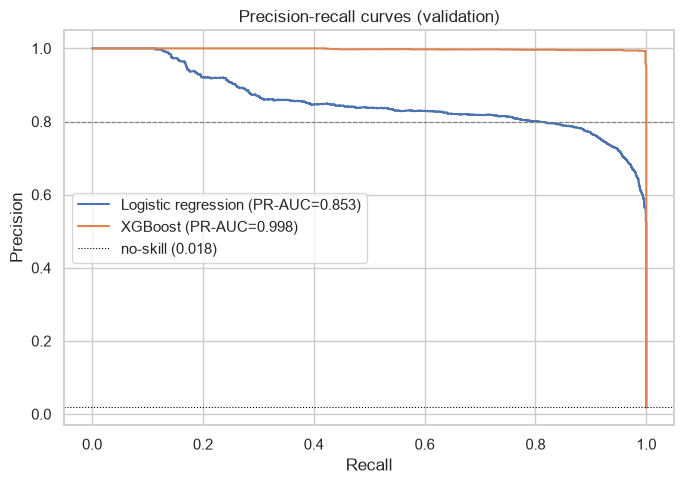

In [18]:
logistic_model = Pipeline([
    ('preprocessor', make_preprocessor(numeric_columns, categorical_columns)),
    ('classifier', LogisticRegression(class_weight='balanced', max_iter=500, solver='lbfgs')),
])
xgb_model = Pipeline([
    ('preprocessor', make_preprocessor(numeric_columns, categorical_columns)),
    ('classifier', XGBClassifier(
        objective='binary:logistic',
        eval_metric='logloss',
        scale_pos_weight=positive_weight,
        **XGB_PARAMS,
    )),
])

binary_models = {
    'Logistic regression': logistic_model,
    'XGBoost': xgb_model,
}
validation_metrics = []
validation_probabilities = {}
for name, model in binary_models.items():
    model.fit(X_train, y_train)
    probabilities = model.predict_proba(X_validation)[:, 1]
    validation_probabilities[name] = probabilities
    validation_metrics.append({'model': name, **evaluate_binary(y_validation, probabilities)})
metrics_table = pd.DataFrame(validation_metrics).set_index('model')

print('--- Binary metrics on validation ---')
display(metrics_table[['PR-AUC', 'ROC-AUC', 'threshold_precision_0.80', 'precision', 'recall_precision_0.80']].astype(float).round(4))

print('--- Binary confusion matrices at the precision >= 0.80 threshold (rows = real, columns = predicted) ---')
for name, r in metrics_table.iterrows():
    print(name)
    display(pd.DataFrame([[r['TN'], r['FP']], [r['FN'], r['TP']]], index=['real 0', 'real 1'], columns=['pred 0', 'pred 1']).astype(int))

fig, ax = plt.subplots(figsize=(7, 5))
for name, p in validation_probabilities.items():
    pr, rc, _ = precision_recall_curve(y_validation, p)
    ax.plot(rc, pr, label=f"{name} (PR-AUC={metrics_table.loc[name, 'PR-AUC']:.3f})")
ax.axhline(0.80, color='grey', ls='--', lw=0.8)
ax.axhline(y_validation.mean(), color='black', ls=':', lw=0.8, label=f'no-skill ({y_validation.mean():.3f})')
ax.set_xlabel('Recall'); ax.set_ylabel('Precision'); ax.set_title('Precision-recall curves (validation)'); ax.legend()
plt.tight_layout()
plt.show()

In [19]:
# Event-level view: share of real failure events (validation) with at least one alert in the 24 h before them
validation_meta['p_xgb'] = validation_probabilities['XGBoost']
thr_xgb = metrics_table.loc['XGBoost', 'threshold_precision_0.80']
positives = validation_meta[(y_validation.values == 1)].reset_index(drop=True).copy()
htf_val = hours_to_next_event(positives[['machineID', 'datetime']], failures, 'failure', COMPS)
positives['failure_time'] = (positives['datetime'] + pd.to_timedelta(np.nanmin(htf_val, axis=1), unit='h')).dt.round('h')
event_detected = positives.groupby(['machineID', 'failure_time'])['p_xgb'].max().ge(thr_xgb)
print(f'XGBoost @ threshold {thr_xgb:.4f}: {int(event_detected.sum())} of {len(event_detected)} validation failure events '
      f'({100 * event_detected.mean():.1f} %) had at least one alert in the 24 h before.')
print('Note: validation has only about 120 failure events, so event-level recall rests on a small sample.')

XGBoost @ threshold 0.0757: 112 of 112 validation failure events (100.0 %) had at least one alert in the 24 h before.
Note: validation has only about 120 failure events, so event-level recall rests on a small sample.


### Multiclass

--- Multiclass confusion matrix: Logistic regression ---


,pred_none,pred_comp1,pred_comp2,pred_comp3,pred_comp4
real_none,139708,649,399,210,382
real_comp1,0,490,0,0,8
real_comp2,0,0,1080,0,0
real_comp3,0,0,0,426,0
real_comp4,0,13,0,0,635


              precision    recall  f1-score   support

        none      1.000     0.988     0.994    141348
       comp1      0.425     0.984     0.594       498
       comp2      0.730     1.000     0.844      1080
       comp3      0.670     1.000     0.802       426
       comp4      0.620     0.980     0.759       648

    accuracy                          0.988    144000
   macro avg      0.689     0.990     0.799    144000
weighted avg      0.993     0.988     0.990    144000

--- Multiclass confusion matrix: XGBoost ---


,pred_none,pred_comp1,pred_comp2,pred_comp3,pred_comp4
real_none,141298,11,22,0,17
real_comp1,0,498,0,0,0
real_comp2,0,0,1080,0,0
real_comp3,0,0,0,426,0
real_comp4,0,0,0,0,648


              precision    recall  f1-score   support

        none      1.000     1.000     1.000    141348
       comp1      0.978     1.000     0.989       498
       comp2      0.980     1.000     0.990      1080
       comp3      1.000     1.000     1.000       426
       comp4      0.974     1.000     0.987       648

    accuracy                          1.000    144000
   macro avg      0.987     1.000     0.993    144000
weighted avg      1.000     1.000     1.000    144000



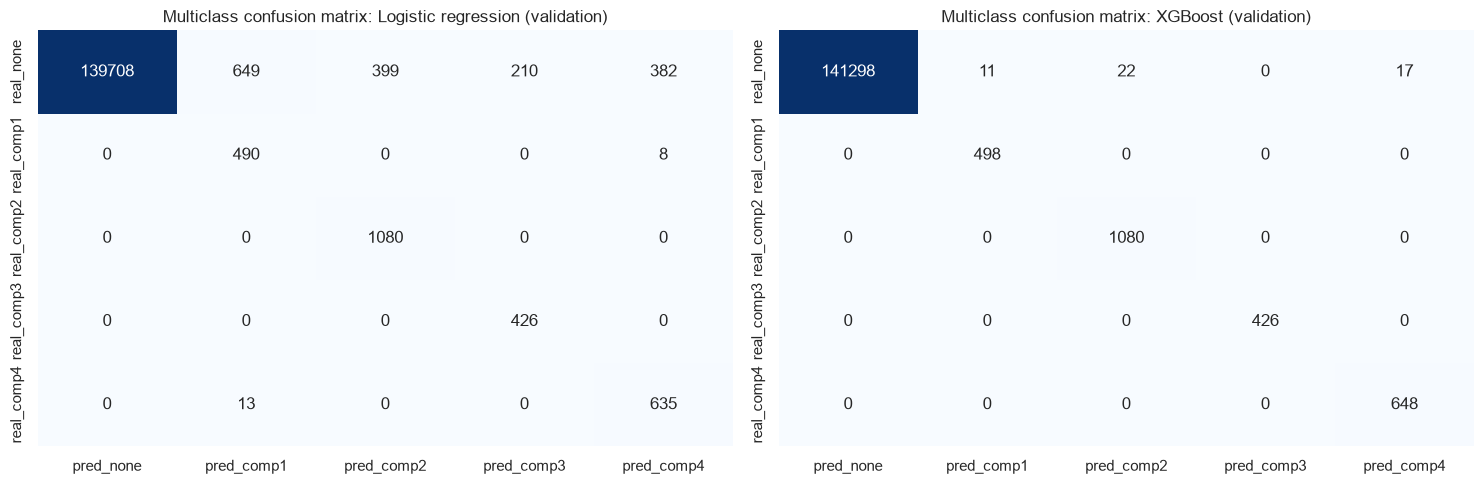

In [20]:
y_train_mc = train['y_multiclass'].astype(int)
y_validation_mc = validation['y_multiclass'].astype(int)
sample_weights = compute_sample_weight('balanced', y_train_mc)

multiclass_logistic = Pipeline([
    ('preprocessor', make_preprocessor(numeric_columns, categorical_columns)),
    ('classifier', LogisticRegression(class_weight='balanced', max_iter=300, solver='lbfgs')),
])
multiclass_xgb = Pipeline([
    ('preprocessor', make_preprocessor(numeric_columns, categorical_columns)),
    ('classifier', XGBClassifier(objective='multi:softprob', eval_metric='mlogloss', **XGB_PARAMS)),
])
multiclass_models = [
    ('Logistic regression', multiclass_logistic, {}),
    ('XGBoost', multiclass_xgb, {'classifier__sample_weight': sample_weights}),
]

multiclass_results = {}
for name, model, fit_kwargs in multiclass_models:
    model.fit(X_train, y_train_mc, **fit_kwargs)
    component_predictions = model.predict(X_validation)
    cm = pd.DataFrame(
        confusion_matrix(y_validation_mc, component_predictions, labels=range(5)),
        index=[f'real_{c}' for c in CLASS_NAMES],
        columns=[f'pred_{c}' for c in CLASS_NAMES],
    )
    multiclass_results[name] = {
        'cm': cm,
        'macro_F1_5_classes': f1_score(y_validation_mc, component_predictions, average='macro'),
        'macro_F1_comp1_to_comp4': f1_score(y_validation_mc, component_predictions, labels=[1, 2, 3, 4], average='macro'),
    }
    print(f'--- Multiclass confusion matrix: {name} ---')
    display(cm)
    print(classification_report(y_validation_mc, component_predictions, labels=range(5),
                                target_names=CLASS_NAMES, zero_division=0, digits=3))

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
for ax, (name, r) in zip(axes, multiclass_results.items()):
    sns.heatmap(r['cm'], annot=True, fmt='d', cmap='Blues', ax=ax, cbar=False)
    ax.set_title(f'Multiclass confusion matrix: {name} (validation)')
plt.tight_layout()
plt.show()

### Leakage ablations: why is the baseline so strong?

A PR-AUC close to 1 needs an explanation. The test below removes one feature group at a time (same XGBoost settings, trained on train, evaluated on validation). If a single group carried a leak, removing it would collapse the score; if the signal is spread over several groups, the score degrades gradually.

In [21]:
groups = {
    'all features': model_feature_columns,
    'without error counts': [c for c in model_feature_columns if not c.startswith('error')],
    'without hours since replacement': [c for c in model_feature_columns if not c.startswith('hours_since')],
    'without 24 h rolling stats': [c for c in model_feature_columns if not (c.endswith('_24h') and ('_mean_' in c or '_std_' in c))],
    'without any rolling stats': [c for c in model_feature_columns if '_mean_' not in c and '_std_' not in c],
    'raw sensors only': sensors,
}
ablation = []
for name, cols in groups.items():
    num = [c for c in cols if c not in categorical_columns]
    cat = [c for c in cols if c in categorical_columns]
    m = Pipeline([
        ('preprocessor', make_preprocessor(num, cat)),
        ('classifier', XGBClassifier(objective='binary:logistic', eval_metric='logloss',
                                     scale_pos_weight=positive_weight, **XGB_PARAMS)),
    ])
    m.fit(train['X'][cols], y_train)
    p = m.predict_proba(validation['X'][cols])[:, 1]
    ablation.append({'feature set': name, 'n_features': len(cols),
                     'PR-AUC': average_precision_score(y_validation, p), 'ROC-AUC': roc_auc_score(y_validation, p)})
ablation = pd.DataFrame(ablation).set_index('feature set')
display(ablation.round(4))

,n_features,PR-AUC,ROC-AUC
feature set,,,
all features,32,0.9980,1.0000
without error counts,26,0.9034,0.9986
without hours since replacement,28,0.9975,1.0000
without 24 h rolling stats,24,0.9985,1.0000
without any rolling stats,16,0.9962,0.9999
raw sensors only,4,0.0787,0.7847


### Feature importance and a visual check on one machine

As the project recommends, the predicted probability is plotted next to the real errors, scheduled replacements and failures of one validation machine.

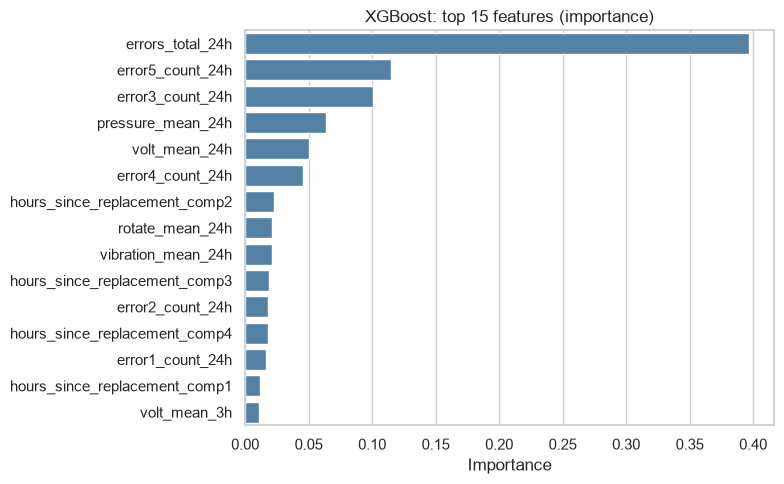

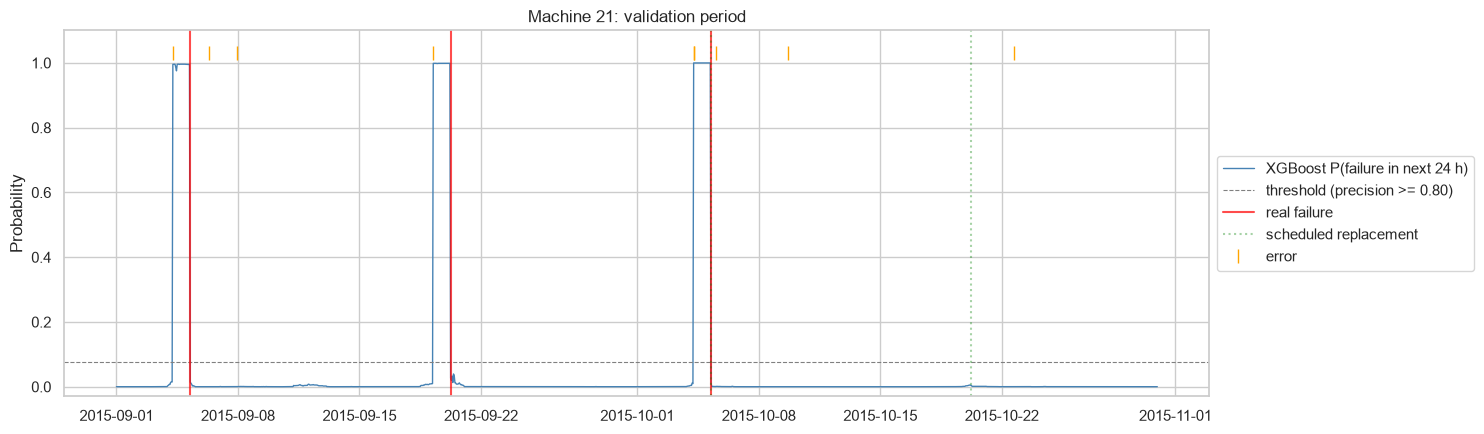

In [22]:
names = xgb_model.named_steps['preprocessor'].get_feature_names_out()
importance = pd.Series(xgb_model.named_steps['classifier'].feature_importances_, index=names).sort_values(ascending=False).head(15)

fig, ax = plt.subplots(figsize=(8, 5))
sns.barplot(x=importance.values, y=[n.split('__', 1)[-1] for n in importance.index], color='steelblue', ax=ax)
ax.set_title('XGBoost: top 15 features (importance)'); ax.set_xlabel('Importance')
plt.tight_layout()
plt.show()

best_machine = event_detected.groupby(level='machineID').size().idxmax()
mv = validation_meta[validation_meta['machineID'] == best_machine]
t_lo, t_hi = mv['datetime'].min(), mv['datetime'].max()
in_range = lambda df_: df_[(df_['machineID'] == best_machine) & df_['datetime'].between(t_lo, t_hi)]

fig, ax = plt.subplots(figsize=(15, 4.5))
ax.plot(mv['datetime'], mv['p_xgb'], lw=1, color='steelblue', label='XGBoost P(failure in next 24 h)')
ax.axhline(thr_xgb, color='grey', ls='--', lw=0.8, label='threshold (precision >= 0.80)')
for i, t in enumerate(in_range(failures)['datetime']):
    ax.axvline(t, color='red', alpha=0.7, label='real failure' if i == 0 else None)
for i, t in enumerate(in_range(maint_flag[~maint_flag['failure_driven']])['datetime']):
    ax.axvline(t, color='green', alpha=0.35, ls=':', label='scheduled replacement' if i == 0 else None)
err_m = in_range(errors)
ax.plot(err_m['datetime'], np.full(len(err_m), 1.03), '|', color='orange', ms=10, label='error')
ax.set_ylim(-0.03, 1.1)
ax.set_title(f'Machine {best_machine}: validation period')
ax.set_ylabel('Probability')
ax.legend(loc='center left', bbox_to_anchor=(1, 0.5))
plt.tight_layout()
plt.show()

### Summary tables for the report

In [23]:
summary_binary = metrics_table[['PR-AUC', 'ROC-AUC', 'threshold_precision_0.80', 'precision', 'recall_precision_0.80']].astype(float).round(4)
summary_multiclass = pd.DataFrame({
    n: {'macro F1 (5 classes)': r['macro_F1_5_classes'], 'macro F1 (comp1-comp4)': r['macro_F1_comp1_to_comp4']}
    for n, r in multiclass_results.items()
}).T.round(4)

print('--- Binary baseline (validation) ---'); display(summary_binary)
print('--- Multiclass baseline (validation) ---'); display(summary_multiclass)
print('--- Imbalance ---'); display(imbalance)
print('--- Feature-group ablation (XGBoost, validation) ---'); display(ablation.round(4))

summary_binary.to_csv(os.path.join(OUT_DIR, 'baseline_binary_validation.csv'))
summary_multiclass.to_csv(os.path.join(OUT_DIR, 'baseline_multiclass_validation.csv'))
imbalance.to_csv(os.path.join(OUT_DIR, 'imbalance_table.csv'))
ablation.to_csv(os.path.join(OUT_DIR, 'ablation_validation.csv'))

--- Binary baseline (validation) ---


,PR-AUC,ROC-AUC,threshold_precision_0.80,precision,recall_precision_0.80
model,,,,,
Logistic regression,0.8531,0.9977,0.9695,0.8001,0.8043
XGBoost,0.9980,1.0000,0.0757,0.8024,1.0000


--- Multiclass baseline (validation) ---


,macro F1 (5 classes),macro F1 (comp1-comp4)
Logistic regression,0.7987,0.7498
XGBoost,0.9932,0.9915


--- Imbalance ---


,rows,positive_rows,positive_rate_%,comp1_rate_%,comp2_rate_%,comp3_rate_%,comp4_rate_%,rows_>1_component
split,,,,,,,,
train,580200,11742,2.024,0.579,0.692,0.373,0.503,714
validation,144000,2652,1.842,0.346,0.750,0.329,0.500,120
test,146400,2682,1.832,0.492,0.725,0.303,0.414,150


--- Feature-group ablation (XGBoost, validation) ---


,n_features,PR-AUC,ROC-AUC
feature set,,,
all features,32,0.9980,1.0000
without error counts,26,0.9034,0.9986
without hours since replacement,28,0.9975,1.0000
without 24 h rolling stats,24,0.9985,1.0000
without any rolling stats,16,0.9962,0.9999
raw sensors only,4,0.0787,0.7847
